# TP3 — Cancelación de reservas de GPU (Grupo 11)

Objetivo: predecir si una reserva de infraestructura GPU se cancelará antes de su ejecución (`canceled_job`), con un proceso iterativo de diagnóstico y optimización, y entregar una función predictora que corra fuera de este notebook.

El conjunto de test se reserva antes del EDA que se usa para tomar decisiones. Las decisiones de preprocesamiento y sus motivos están resumidos en la sección 4.

Para ejecutarlo hacen falta, en la misma carpeta que el notebook, el dataset `gpu_resource_reservations.csv` y `predictor_v1_Grupo_11.py` (incluido en el paquete del predictor), que tiene las transformaciones fijas y la receta del modelo final.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
# Dataset de la consigna, en la misma carpeta que el notebook.
DATA_PATH = Path('gpu_resource_reservations.csv')
TARGET = 'canceled_job'

# Colores de los gráficos: una sola serie (azul) y una referencia neutra (gris).
BLUE = '#2a78d6'
REFERENCE = '#7a7974'

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

## 1. Carga y verificación de integridad

En esta etapa sólo se verifican el esquema, la consistencia interna y lo que hace falta para diseñar la partición: el balance de clases (para estratificar), las columnas que delatan el objetivo y los duplicados. Las relaciones de las variables con el objetivo que influyen en el preprocesamiento se analizan después de reservar test.

In [2]:
df = pd.read_csv(DATA_PATH)

# Variables documentadas en la consigna, en el orden en que las describe.
DOCUMENTED_FEATURES = [
    'hours_before_execution', 'execution_year', 'execution_month', 'execution_week',
    'execution_day', 'peak_gpu_hours', 'offpeak_gpu_hours', 'num_primary_processes',
    'num_auxiliary_processes', 'num_background_processes', 'service_tier',
    'client_region', 'client_type', 'request_channel', 'returning_client',
    'previous_job_cancellations', 'successful_previous_jobs', 'reserved_gpu_type',
    'assigned_gpu_type', 'resource_modifications', 'reservation_commitment',
    'orchestration_agent_id', 'organization_id', 'queue_wait_time', 'workload_profile',
    'estimated_cost_per_hour', 'reserved_storage_units', 'special_resource_requests',
]
UNDOCUMENTED = [c for c in df.columns if c not in DOCUMENTED_FEATURES + [TARGET]]

assert df.shape == (47842, 34)
assert len(DOCUMENTED_FEATURES) == 28
assert set(DOCUMENTED_FEATURES + [TARGET]) <= set(df.columns)
print(f'{df.shape[0]} filas y {df.shape[1]} columnas')
print('Columnas no documentadas en la consigna:', UNDOCUMENTED)

missing = df.isna().sum().loc[lambda s: s > 0].to_frame('faltantes')
missing['porcentaje'] = 100 * missing['faltantes'] / len(df)
display(missing.round(2))

47842 filas y 34 columnas
Columnas no documentadas en la consigna: ['execution_status', 'execution_status_date', 'total_processes', 'total_gpu_hours', 'high_value_client']


,faltantes,porcentaje
num_auxiliary_processes,1,0.00
client_region,20,0.04
orchestration_agent_id,5035,10.52
organization_id,45540,95.19


### 1.1 Columnas no documentadas y leakage

El CSV trae cinco columnas que la consigna no describe. Antes de decidir qué hacer con ellas hay que saber qué miden.

In [3]:
display(pd.crosstab(df['execution_status'], df[TARGET], margins=True))

execution_date = pd.to_datetime(dict(
    year=df['execution_year'], month=df['execution_month'], day=df['execution_day'],
))
status_delay = (pd.to_datetime(df['execution_status_date']) - execution_date).dt.days
print('Días entre la fecha de ejecución programada y execution_status_date:')
display(status_delay.groupby(df['execution_status']).describe()[['min', 'mean', 'max']].round(1))

total_processes = (df['num_primary_processes'] + df['num_auxiliary_processes'].fillna(0)
                   + df['num_background_processes'])
assert (df['total_processes'] == total_processes).all()
assert (df['total_gpu_hours'] == df['peak_gpu_hours'] + df['offpeak_gpu_hours']).all()
print('total_processes y total_gpu_hours son sumas exactas de columnas documentadas.')

print('estimated_cost_per_hour según high_value_client:')
display(df.groupby('high_value_client')['estimated_cost_per_hour'].describe().round(2))

canceled_job,0,1,All
execution_status,,,
canceled,0,19416,19416
completed,27887,0,27887
no_show,0,539,539
All,27887,19955,47842


Días entre la fecha de ejecución programada y execution_status_date:


,min,mean,max
execution_status,,,
canceled,-526.0,-90.3,0.0
completed,0.0,2.9,57.0
no_show,0.0,0.0,0.0


total_processes y total_gpu_hours son sumas exactas de columnas documentadas.
estimated_cost_per_hour según high_value_client:


,count,mean,std,min,25%,50%,75%,max
high_value_client,,,,,,,,
0,36525.0,4.55,1.24,0.0,3.75,4.55,5.49,6.62
1,11317.0,7.56,3.24,0.0,6.84,7.50,8.50,270.00


- **`execution_status` es el objetivo con otro nombre:** `canceled` y `no_show` coinciden siempre con `canceled_job = 1`, y `completed` con `0`.
- **`execution_status_date` también lo delata:** en las canceladas cae en promedio 90 días antes de la ejecución programada; en las completadas, el mismo día o después; en los `no_show`, siempre el mismo día.
- Las dos describen lo que pasó con la reserva, así que no existen en el momento de predecir. Se excluyen.
- `total_processes` y `total_gpu_hours` son sumas exactas de variables documentadas: no agregan información. Si hacen falta, se recalculan dentro del pipeline.
- `high_value_client` no tiene definición y no es un simple umbral del costo por hora (los rangos de ambos grupos se superponen). Se excluye para que el predictor no dependa de una columna que podría no venir en los datos de evaluación.

### 1.2 Duplicados: reservas en lote

Se buscan filas idénticas en todas las variables, sin contar el objetivo ni las dos columnas de estado.

In [4]:
LEAKY_STATUS = ['execution_status', 'execution_status_date']


def duplicate_key(frame):
    # Identifica filas idénticas en las variables disponibles al predecir.
    columns = [c for c in frame.columns if c not in LEAKY_STATUS + [TARGET]]
    return pd.util.hash_pandas_object(frame[columns], index=False)


key = duplicate_key(df)
group_size = key.map(key.value_counts())
has_twin = group_size > 1

print(f'Filas que son copia de una anterior: {key.duplicated().sum()}')
print(f'Filas en grupos de reservas idénticas: {has_twin.sum()} ({has_twin.mean():.1%}), '
      f'en {key[has_twin].nunique()} grupos')

size_bins = pd.cut(group_size, [0, 1, 2, 5, 10, 50, np.inf],
                   labels=['única', '2', '3-5', '6-10', '11-50', 'más de 50'])
display(df.groupby(size_bins, observed=True)[TARGET].agg(filas='size', tasa_cancelacion='mean')
        .style.format({'tasa_cancelacion': '{:.1%}'}))

composition = pd.DataFrame({
    'locked_allocation': df['reservation_commitment'].eq('locked_allocation'),
    'research_consortium': df['client_type'].eq('research_consortium'),
}).groupby(has_twin.map({True: 'con gemelas', False: 'únicas'})).mean()
display(composition.style.format('{:.1%}'))

mixed = df.groupby(key.values)[TARGET].nunique().loc[lambda s: s > 1]
print(f'Grupos idénticos con etiquetas distintas: {len(mixed)} '
      f'({key.isin(mixed.index).sum()} filas)')

Filas que son copia de una anterior: 15936
Filas en grupos de reservas idénticas: 19435 (40.6%), en 3499 grupos


,filas,tasa_cancelacion
única,28407,28.4%
2,4200,35.7%
3-5,2686,37.8%
6-10,2106,50.6%
11-50,7560,73.9%
más de 50,2883,94.5%


,locked_allocation,research_consortium
con gemelas,39.9%,37.7%
únicas,0.4%,3.1%


Grupos idénticos con etiquetas distintas: 79 (531 filas)


- Un tercio de las filas repite otra fila exacta, y el 41 % pertenece a algún grupo de reservas idénticas. Hay grupos de más de 50 copias.
- La tasa de cancelación crece con el tamaño del grupo: 28 % en las filas únicas, 74 % en grupos de 11 a 50 copias y 95 % en los de más de 50.
- Las filas con gemelas son, sobre todo, `locked_allocation` (40 %, frente a 0,4 % en las únicas) y `research_consortium` (38 %, frente a 3 %). **Inferencia:** no parecen errores de carga sino reservas en lote, como un consorcio que pide decenas de trabajos iguales y los cancela juntos. Eliminarlas borraría justo el segmento que más se cancela y cambiaría la distribución.
- Hay 79 grupos idénticos (531 filas) con etiquetas distintas: para esas filas, ningún modelo puede acertar siempre. Es una cota de error irreducible.
- **Idea para más adelante:** el tamaño del lote es una señal muy fuerte, pero el dataset no tiene un identificador de lote. Es un candidato para el punto 3.4 (qué datos adicionales registrar).

**Decisión:** se conservan los duplicados. Como pueden caer a ambos lados de una partición aleatoria, la validación principal se complementa con una validación agrupada que nunca separa filas idénticas, y en test se reportan aparte las filas con gemela en entrenamiento.

## 2. Reserva de test

Se reserva el 20 % con un split aleatorio estratificado por `canceled_job`. El balance (41,7 % de canceladas) es moderado, pero estratificar mantiene la misma proporción en desarrollo y test.

**Por qué aleatorio y no temporal o agrupado.** No sabemos cómo armó la cátedra el conjunto con que mide el Model Score de la competencia. **Inferencia:** el período (julio de 2015 a agosto de 2017) y las columnas sugieren que viene del mismo conjunto de reservas que este archivo; en ese caso, un split aleatorio imita mejor esa evaluación. A cambio, la estimación sobre reservas realmente nuevas se obtiene con la validación agrupada y con las filas de test sin gemela en desarrollo.

Test no se usa para elegir preprocesamiento, variables, modelo, hiperparámetros ni umbral.

In [5]:
TEST_SIZE = 0.20

X = df.drop(columns=TARGET)
y = df[TARGET]

X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y,
)

# Grupos de filas idénticas: se usan para la validación agrupada y para separar test.
groups_dev = duplicate_key(X_dev).to_numpy()
test_has_twin_in_dev = duplicate_key(X_test).isin(set(groups_dev)).to_numpy()

assert len(X_dev) == 38273 and len(X_test) == 9569
assert X_dev.index.intersection(X_test.index).empty
print(f'Desarrollo: {len(X_dev)} filas, {y_dev.sum()} canceladas ({y_dev.mean():.2%})')
print(f'Test reservado: {len(X_test)} filas, {y_test.sum()} canceladas ({y_test.mean():.2%})')
print(f'Filas de test con una gemela exacta en desarrollo: {test_has_twin_in_dev.mean():.1%}')

Desarrollo: 38273 filas, 15964 canceladas (41.71%)
Test reservado: 9569 filas, 3991 canceladas (41.71%)
Filas de test con una gemela exacta en desarrollo: 38.6%


## 3. EDA de desarrollo

Desde acá se trabaja sólo con `X_dev` e `y_dev`. Cada observación tiene que traducirse en una decisión sobre el preprocesamiento, las variables o la interpretación de los errores.

In [6]:
dev = X_dev.copy()
dev[TARGET] = y_dev
global_rate = y_dev.mean()


def cohort_table(column, frame=dev):
    table = (frame.groupby(column, dropna=False)[TARGET]
             .agg(filas='size', tasa_cancelacion='mean')
             .sort_values('filas', ascending=False))
    table['porcentaje_filas'] = table['filas'] / len(frame)
    return table


def show_cohort(column, frame=dev):
    display(cohort_table(column, frame).style.format(
        {'tasa_cancelacion': '{:.1%}', 'porcentaje_filas': '{:.1%}'}))


def plot_rates(ax, table, title, min_rows=20):
    # Barras horizontales con la tasa de cancelación y la tasa global como referencia.
    table = table.loc[table['filas'] >= min_rows].iloc[::-1]
    labels = table.index.astype(str)
    ax.barh(labels, table['tasa_cancelacion'], color=BLUE, height=0.6)
    ax.axvline(global_rate, color=REFERENCE, linestyle='--', linewidth=1)
    for position, (rate, rows) in enumerate(zip(table['tasa_cancelacion'], table['filas'])):
        ax.text(rate + 0.015, position, f'{rate:.0%}  (n = {rows})', va='center', fontsize=8)
    ax.set_xlim(0, 1.2)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(title)
    ax.grid(axis='y', visible=False)

### 3.1 Faltantes y cardinalidad

In [7]:
missing_dev = []
for column in ['organization_id', 'orchestration_agent_id', 'client_region', 'num_auxiliary_processes']:
    is_missing = dev[column].isna()
    missing_dev.append({
        'variable': column,
        'faltantes': int(is_missing.sum()),
        'porcentaje': is_missing.mean(),
        'tasa_si_falta': dev.loc[is_missing, TARGET].mean(),
        'tasa_si_no_falta': dev.loc[~is_missing, TARGET].mean(),
    })
display(pd.DataFrame(missing_dev).set_index('variable').style.format(
    {'porcentaje': '{:.1%}', 'tasa_si_falta': '{:.1%}', 'tasa_si_no_falta': '{:.1%}'}))

MIN_CATEGORY_ROWS = 50
categorical_columns = ['service_tier', 'client_region', 'client_type', 'request_channel',
                       'reserved_gpu_type', 'reservation_commitment', 'workload_profile',
                       'orchestration_agent_id', 'organization_id']
cardinality = []
for column in categorical_columns:
    counts = dev[column].value_counts()
    frequent = counts[counts >= MIN_CATEGORY_ROWS]
    cardinality.append({
        'variable': column,
        'categorias': len(counts),
        f'con_{MIN_CATEGORY_ROWS}_filas_o_mas': len(frequent),
        'cobertura_frecuentes': frequent.sum() / len(dev),
    })
display(pd.DataFrame(cardinality).set_index('variable').style.format({'cobertura_frecuentes': '{:.1%}'}))

,faltantes,porcentaje,tasa_si_falta,tasa_si_no_falta
variable,,,,
organization_id,36411,95.1%,42.7%,23.3%
orchestration_agent_id,4058,10.6%,32.6%,42.8%
client_region,16,0.0%,87.5%,41.7%
num_auxiliary_processes,1,0.0%,100.0%,41.7%


,categorias,con_50_filas_o_mas,cobertura_frecuentes
variable,,,
service_tier,4,3,100.0%
client_region,139,36,97.3%
client_type,8,7,100.0%
request_channel,5,4,100.0%
reserved_gpu_type,8,6,100.0%
reservation_commitment,3,2,100.0%
workload_profile,4,4,100.0%
orchestration_agent_id,187,51,85.7%
organization_id,160,8,2.7%


- **`organization_id`** falta en el 95 % de las filas y sólo 8 organizaciones tienen 50 filas o más. El ID no se puede aprender, pero que exista una organización sí informa: esas reservas se cancelan bastante menos. **Decisión:** reemplazarlo por la binaria `has_organization`.
- **`orchestration_agent_id`** falta en el 11 % y tiene 187 valores. Es un identificador, no una cantidad: se trata como categórica. El faltante (reserva sin agente) tiene su propia tasa, así que se codifica como una categoría más.
- **`client_region`** tiene 139 valores y 20 faltantes. Las 36 regiones con 50 filas o más cubren el 97 % de desarrollo.
- **Categorías raras:** en todas las categóricas, las categorías con menos de 50 filas en el fold de entrenamiento se agrupan en una categoría "infrecuente". Eso incluye los `unknown` de una sola fila de `client_type` y `request_channel`. El umbral se aprende dentro de cada fold (con `min_frequency` del encoder), así que no produce leakage.
- **`num_auxiliary_processes`** tiene un solo faltante: se imputa con la mediana de entrenamiento.

### 3.2 Cohortes pedidas por la consigna

La consigna pide analizar en particular `client_type`, `service_tier` y `reserved_gpu_type`. Acá se describe cómo varía la tasa de cancelación; el rendimiento del modelo por cohorte se analiza en la sección de errores.

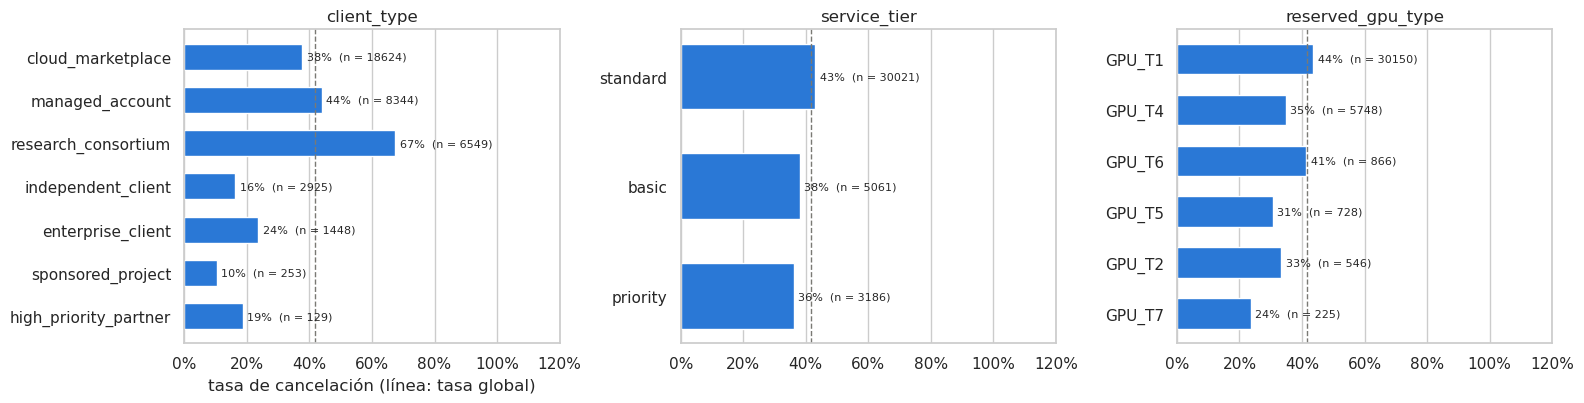

,filas,tasa_cancelacion,porcentaje_filas
client_type,,,
cloud_marketplace,18624,37.7%,48.7%
managed_account,8344,43.9%,21.8%
research_consortium,6549,67.4%,17.1%
independent_client,2925,16.3%,7.6%
enterprise_client,1448,23.5%,3.8%
sponsored_project,253,10.3%,0.7%
high_priority_partner,129,18.6%,0.3%
unknown,1,100.0%,0.0%


,filas,tasa_cancelacion,porcentaje_filas
service_tier,,,
standard,30021,42.9%,78.4%
basic,5061,38.1%,13.2%
priority,3186,36.1%,8.3%
enterprise,5,60.0%,0.0%


,filas,tasa_cancelacion,porcentaje_filas
reserved_gpu_type,,,
GPU_T1,30150,43.6%,78.8%
GPU_T4,5748,34.8%,15.0%
GPU_T6,866,41.3%,2.3%
GPU_T5,728,30.6%,1.9%
GPU_T2,546,33.3%,1.4%
GPU_T7,225,23.6%,0.6%
GPU_T3,8,62.5%,0.0%
GPU_T12,2,100.0%,0.0%


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, column in zip(axes, ['client_type', 'service_tier', 'reserved_gpu_type']):
    plot_rates(ax, cohort_table(column), column)
axes[0].set_xlabel('tasa de cancelación (línea: tasa global)')
plt.tight_layout()
plt.show()

for column in ['client_type', 'service_tier', 'reserved_gpu_type']:
    show_cohort(column)

- **`client_type` es la cohorte que más separa:** `research_consortium` se cancela en el 67 % de los casos e `independent_client` en el 16 %, frente a una tasa global del 42 %.
- **`service_tier`** separa poco: de 36 % (`priority`) a 43 % (`standard`). `enterprise` tiene 5 filas.
- **`reserved_gpu_type`:** `GPU_T1` concentra el 79 % de las reservas y es la de mayor tasa. Las demás varían entre 24 % y 41 %. `GPU_T3` y `GPU_T12` tienen menos de 10 filas.

In [9]:
commitment_share = pd.crosstab(dev['client_type'], dev['reservation_commitment'], normalize='index')
commitment_rate = pd.crosstab(dev['client_type'], dev['reservation_commitment'],
                              values=dev[TARGET], aggfunc='mean')
print('Proporción de cada compromiso dentro de cada tipo de cliente:')
display(commitment_share.style.format('{:.1%}'))
print('Tasa de cancelación por tipo de cliente y compromiso:')
display(commitment_rate.style.format('{:.1%}', na_rep='—'))

Proporción de cada compromiso dentro de cada tipo de cliente:


reservation_commitment,flexible_commitment,locked_allocation,no_commitment
client_type,,,
cloud_marketplace,0.0%,0.1%,99.9%
enterprise_client,0.1%,14.2%,85.7%
high_priority_partner,0.0%,0.0%,100.0%
independent_client,0.0%,0.3%,99.7%
managed_account,0.0%,30.5%,69.4%
research_consortium,0.0%,53.5%,46.5%
sponsored_project,0.0%,0.0%,100.0%
unknown,0.0%,0.0%,100.0%


Tasa de cancelación por tipo de cliente y compromiso:


reservation_commitment,flexible_commitment,locked_allocation,no_commitment
client_type,,,
cloud_marketplace,100.0%,83.3%,37.6%
enterprise_client,50.0%,95.6%,11.6%
high_priority_partner,—,—,18.6%
independent_client,100.0%,88.9%,16.1%
managed_account,0.0%,100.0%,19.2%
research_consortium,—,99.9%,30.1%
sponsored_project,—,—,10.3%
unknown,—,—,100.0%


La tasa alta de `research_consortium` se explica en gran parte por el compromiso: el 53 % de sus reservas son `locked_allocation`, que se cancela casi siempre. Dentro de `no_commitment`, su tasa baja al 30 %, igual que la del promedio. Lo mismo pasa, en menor medida, con `managed_account`. Para el análisis de errores conviene mirar las cohortes junto con el compromiso: una cohorte con tasa alta no es necesariamente una cohorte difícil.

### 3.3 Otras categóricas y binarias

In [10]:
for column in ['reservation_commitment', 'workload_profile', 'request_channel', 'returning_client']:
    show_cohort(column)

region = cohort_table('client_region')
print('Regiones con más reservas:')
display(region.head(8).style.format({'tasa_cancelacion': '{:.1%}', 'porcentaje_filas': '{:.1%}'}))

,filas,tasa_cancelacion,porcentaje_filas
reservation_commitment,,,
no_commitment,31982,30.3%,83.6%
locked_allocation,6279,99.7%,16.4%
flexible_commitment,12,75.0%,0.0%


,filas,tasa_cancelacion,porcentaje_filas
workload_profile,,,
single_experiment,28659,46.0%,74.9%
multi_run_experiment,8347,26.9%,21.8%
long_term_contract,1128,47.3%,2.9%
team_project,139,8.6%,0.4%


,filas,tasa_cancelacion,porcentaje_filas
request_channel,,,
broker_platform,33299,45.2%,87.0%
api_direct,3254,17.4%,8.5%
enterprise_portal,1635,20.9%,4.3%
scheduler_gateway,84,13.1%,0.2%
unknown,1,100.0%,0.0%


,filas,tasa_cancelacion,porcentaje_filas
returning_client,,,
0,37320,42.3%,97.5%
1,953,18.5%,2.5%


Regiones con más reservas:


,filas,tasa_cancelacion,porcentaje_filas
client_region,,,
PRT,14867,65.1%,38.8%
FRA,4192,20.5%,11.0%
DEU,3035,16.9%,7.9%
GBR,2608,29.6%,6.8%
ESP,2234,28.5%,5.8%
ITA,1575,37.4%,4.1%
BEL,887,19.6%,2.3%
BRA,829,39.7%,2.2%


- **`reservation_commitment = locked_allocation`** (16 % de las filas) se cancela en el 99,7 % de los casos. Es la señal individual más fuerte del dataset. `flexible_commitment` tiene 12 filas.
- **`workload_profile`:** `multi_run_experiment` (27 %) y `team_project` (9 %) se cancelan mucho menos que `single_experiment` (46 %).
- **`request_channel`:** el 87 % entra por `broker_platform`, con 45 % de cancelación; los canales directos se cancelan entre 13 % y 21 %.
- **`returning_client`:** los clientes que vuelven se cancelan menos (19 % frente a 42 %), pero son sólo el 2,5 %.
- **`client_region`:** `PRT` concentra el 39 % de las reservas y se cancela en el 65 % de los casos, frente al 21 % de `FRA` y el 17 % de `DEU`.

### 3.4 Numéricas

,auc_univariado,asimetria,maximo
hours_before_execution,0.683,1.340,629.0
special_resource_requests,0.665,1.416,5.0
previous_job_cancellations,0.571,14.874,13.0
resource_modifications,0.563,6.689,17.0
offpeak_gpu_hours,0.533,2.499,200.0
estimated_cost_per_hour,0.524,36.467,270.0
num_primary_processes,0.523,-0.437,4.0
queue_wait_time,0.523,11.184,391.0
reserved_storage_units,0.520,6.289,2.0
successful_previous_jobs,0.515,22.752,70.0


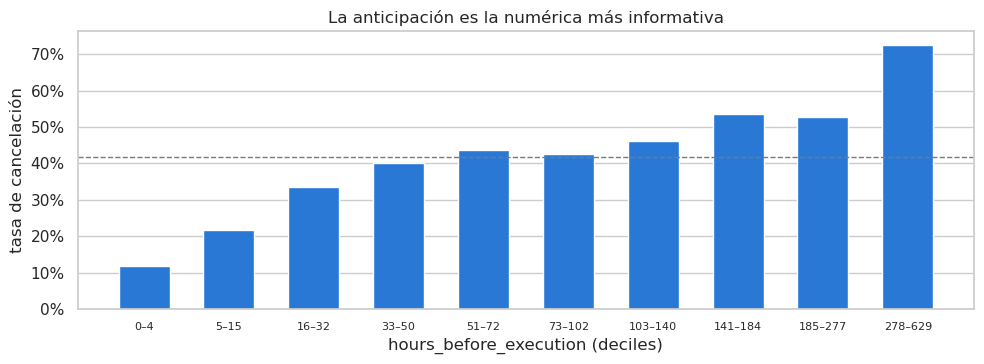

In [11]:
numeric_columns = [
    'hours_before_execution', 'peak_gpu_hours', 'offpeak_gpu_hours', 'num_primary_processes',
    'num_auxiliary_processes', 'num_background_processes', 'previous_job_cancellations',
    'successful_previous_jobs', 'resource_modifications', 'estimated_cost_per_hour',
    'reserved_storage_units', 'special_resource_requests', 'queue_wait_time',
    'execution_year', 'execution_month', 'execution_week', 'execution_day',
]
numeric_summary = pd.DataFrame({
    # AUC univariado simetrizado: 0,5 = sin señal, 1 = separa perfectamente.
    'auc_univariado': {c: max(a, 1 - a) for c in numeric_columns
                       for a in [roc_auc_score(y_dev, dev[c].fillna(0))]},
    'asimetria': dev[numeric_columns].skew(),
    'maximo': dev[numeric_columns].max(),
}).sort_values('auc_univariado', ascending=False)
display(numeric_summary.round(3))

deciles = pd.qcut(dev['hours_before_execution'], 10, duplicates='drop')
lead_rate = dev.groupby(deciles, observed=True)[TARGET].mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(len(lead_rate)), lead_rate.values, color=BLUE, width=0.6)
ax.axhline(global_rate, color=REFERENCE, linestyle='--', linewidth=1)
ax.set_xticks(range(len(lead_rate)))
ax.set_xticklabels([f'{0 if i.left < 0 else int(i.left) + 1}–{int(i.right)}' for i in lead_rate.index], fontsize=8)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel('hours_before_execution (deciles)')
ax.set_ylabel('tasa de cancelación')
ax.set_title('La anticipación es la numérica más informativa')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

In [12]:
for column in ['special_resource_requests', 'reserved_storage_units', 'previous_job_cancellations']:
    show_cohort(column)

,filas,tasa_cancelacion,porcentaje_filas
special_resource_requests,,,
0,23070,55.0%,60.3%
1,10406,21.7%,27.2%
2,3922,22.5%,10.2%
3,754,17.1%,2.0%
4,105,11.4%,0.3%
5,16,6.2%,0.0%


,filas,tasa_cancelacion,porcentaje_filas
reserved_storage_units,,,
0,37368,42.7%,97.6%
1,904,0.0%,2.4%
2,1,0.0%,0.0%


,filas,tasa_cancelacion,porcentaje_filas
previous_job_cancellations,,,
0,35689,38.0%,93.2%
1,2473,96.3%,6.5%
2,40,15.0%,0.1%
3,23,8.7%,0.1%
4,14,7.1%,0.0%
6,14,35.7%,0.0%
5,8,0.0%,0.0%
13,8,100.0%,0.0%
11,4,25.0%,0.0%


- **`hours_before_execution`** es la numérica más informativa (AUC univariado 0,68): la tasa sube de 12 % en las reservas hechas con 4 horas o menos de anticipación a 73 % en las de más de 277. La relación es monótona, buena para cualquier modelo.
- **`special_resource_requests`:** sin pedidos especiales se cancela el 55 %; con al menos uno, alrededor del 22 %.
- **`reserved_storage_units > 0`:** ninguna de las 905 reservas con almacenamiento reservado se canceló.
- **`previous_job_cancellations`** no es monótona: con 1 cancelación previa, el 96 % se cancela; con 2 o más, la tasa vuelve a bajar. Un modelo lineal no captaría esa forma sin transformarla; un árbol sí.
- **Asimetría:** `estimated_cost_per_hour`, `successful_previous_jobs`, `previous_job_cancellations` y `queue_wait_time` tienen colas muy largas. Importa sólo para modelos sensibles a la escala.
- Las variables de fecha casi no separan por sí solas (AUC ≈ 0,51), pero pueden interactuar con otras.

### 3.5 Zona gris de leakage

Se decidió excluir `assigned_gpu_type` y `queue_wait_time` porque su definición en la consigna indica que se conocen recién al asignar recursos para la ejecución. Acá se documenta cuánta señal tienen, para entender qué se pierde; el impacto en el modelo se mide una vez en el paso del baseline.

In [13]:
gray_zone = pd.DataFrame({
    'GPU asignada distinta de la pedida': dev['assigned_gpu_type'].ne(dev['reserved_gpu_type']),
    'queue_wait_time > 0': dev['queue_wait_time'].gt(0),
    'resource_modifications > 0': dev['resource_modifications'].gt(0),
})
rows = []
for name, flag in gray_zone.items():
    rows.append({'condición': name, 'filas': int(flag.sum()), 'porcentaje': flag.mean(),
                 'tasa_si_se_cumple': dev.loc[flag, TARGET].mean(),
                 'tasa_si_no': dev.loc[~flag, TARGET].mean()})
display(pd.DataFrame(rows).set_index('condición').style.format(
    {'porcentaje': '{:.1%}', 'tasa_si_se_cumple': '{:.1%}', 'tasa_si_no': '{:.1%}'}))
show_cohort('resource_modifications')

,filas,porcentaje,tasa_si_se_cumple,tasa_si_no
condición,,,,
GPU asignada distinta de la pedida,3464,9.1%,6.0%,45.3%
queue_wait_time > 0,1585,4.1%,68.5%,40.6%
resource_modifications > 0,4921,12.9%,17.5%,45.3%


,filas,tasa_cancelacion,porcentaje_filas
resource_modifications,,,
0,33352,45.3%,87.1%
1,3470,14.7%,9.1%
2,1069,26.3%,2.8%
3,223,18.4%,0.6%
4,96,14.6%,0.3%
5,23,30.4%,0.1%
6,16,50.0%,0.0%
7,7,0.0%,0.0%
8,5,0.0%,0.0%


- **GPU asignada distinta de la pedida:** esas reservas se cancelan sólo en el 6 %, frente al 45 % del resto. **Inferencia:** cambiar la GPU es algo que ocurre al preparar la ejecución; en una reserva cancelada antes, la asignada queda igual a la pedida. Es información del futuro, y por eso es tan buena. Se excluye.
- **`queue_wait_time > 0`:** se cancelan más (68 % frente a 41 %). También se excluye, por su definición.
- **`resource_modifications`:** las reservas modificadas se cancelan menos. Su definición en la consigna, a diferencia de las otras dos, no dice que se mida al ejecutar ("número de modificaciones realizadas sobre la reserva original"). **Decisión:** se conserva, y en el paso del baseline se mide cuánto aporta. Si el aporte fuera desproporcionado, sería una señal de que también cuenta cambios tardíos, y se discutiría en la defensa.

### 3.6 Evolución temporal

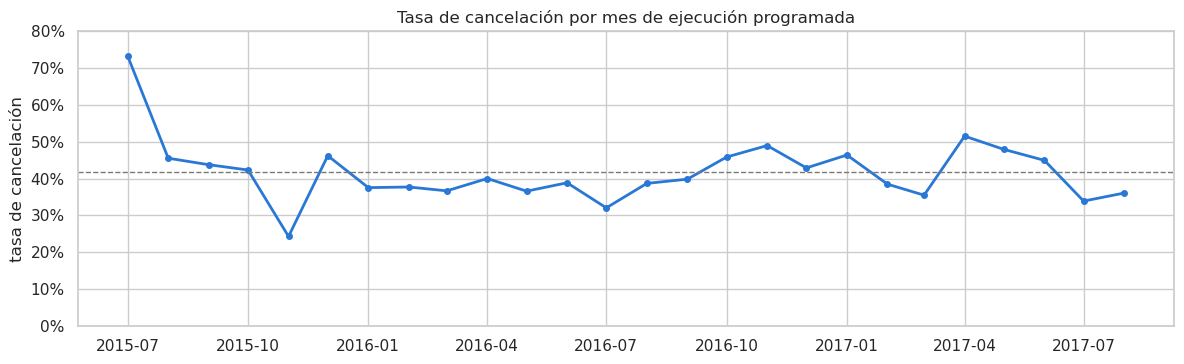

,filas,tasa_cancelacion,porcentaje_filas
execution_year,,,
2015,6544,45.3%,17.1%
2016,18526,40.0%,48.4%
2017,13203,42.4%,34.5%


In [14]:
period = pd.PeriodIndex.from_fields(year=dev['execution_year'], month=dev['execution_month'], freq='M')
monthly = dev.groupby(period)[TARGET].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(monthly.index.to_timestamp(), monthly['mean'], color=BLUE, linewidth=2, marker='o', markersize=4)
ax.axhline(global_rate, color=REFERENCE, linestyle='--', linewidth=1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 0.8)
ax.set_ylabel('tasa de cancelación')
ax.set_title('Tasa de cancelación por mes de ejecución programada')
plt.tight_layout()
plt.show()

display(cohort_table('execution_year').sort_index().style.format(
    {'tasa_cancelacion': '{:.1%}', 'porcentaje_filas': '{:.1%}'}))

La tasa mensual oscila entre 24 % y 73 %, pero sin una tendencia sostenida: por año va de 45 % (2015, sólo julio a diciembre) a 40 % (2016) y 42 % (2017). No hay un cambio de distribución que obligue a validar en el tiempo. Las variables de fecha se conservan como numéricas. **Limitación:** para reservas de años posteriores a 2017, un modelo de árboles trataría `execution_year` como si fuera 2017; se revisa su aporte en la etapa de selección de variables.

### 3.7 Valores extremos y reservas vacías

In [15]:
print('Mayores costos por hora:', dev['estimated_cost_per_hour'].nlargest(4).round(2).tolist())

quality = pd.DataFrame({
    'costo por hora igual a 0': dev['estimated_cost_per_hour'].eq(0),
    'sin procesos (los tres conteos en 0)': (dev['num_primary_processes'] + dev['num_auxiliary_processes'].fillna(0)
                                            + dev['num_background_processes']).eq(0),
    'sin horas GPU': (dev['peak_gpu_hours'] + dev['offpeak_gpu_hours']).eq(0),
})
rows = [{'condición': name, 'filas': int(flag.sum()), 'tasa_cancelacion': dev.loc[flag, TARGET].mean()}
        for name, flag in quality.items()]
display(pd.DataFrame(rows).set_index('condición').style.format({'tasa_cancelacion': '{:.1%}'}))

Mayores costos por hora: [270.0, 25.5, 18.62, 17.62]


,filas,tasa_cancelacion
condición,,
costo por hora igual a 0,578,10.9%
sin procesos (los tres conteos en 0),79,8.9%
sin horas GPU,155,5.2%


- Hay un costo de 270 USD por hora, diez veces el siguiente (25,5). No se puede saber si es un error. No se elimina: los modelos de árboles no se ven afectados, y para modelos sensibles a la escala se aplica `log1p` al costo.
- Las reservas con costo 0 (578), sin procesos (79) o sin horas GPU (155) se cancelan muy poco. Pueden ser reservas internas o de cortesía. Se conservan y se siguen como cohortes en el análisis de errores.

## 4. Decisiones de preprocesamiento

| Variable o grupo | Decisión | Motivo |
|---|---|---|
| `execution_status`, `execution_status_date` | Excluir | Determinan el objetivo: describen lo que pasó con la reserva. |
| `assigned_gpu_type`, `queue_wait_time` | Excluir, y medir una vez cuánto inflarían | Su definición indica que se conocen al asignar recursos para ejecutar. |
| `total_processes`, `total_gpu_hours`, `high_value_client` | No usar como entrada | No documentadas. Los totales son sumas exactas y se pueden recalcular; `high_value_client` no tiene definición. |
| `organization_id` | Binaria `has_organization` | 95 % de faltantes; el ID no se puede aprender, pero su presencia informa. |
| `orchestration_agent_id`, `client_region` | Categóricas, con el faltante como categoría | Son identificadores, no cantidades. |
| Categorías con menos de 50 filas | Agrupar como "infrecuente" dentro de cada fold | Evita estimar tasas con muy pocos ejemplos y absorbe categorías nuevas. |
| `num_auxiliary_processes` | Imputar con la mediana de entrenamiento | Un solo faltante. |
| `resource_modifications` | Conservar y medir su aporte | Su definición no la ubica después de la ejecución. |
| Duplicados | Conservar | Parecen reservas en lote reales. Se controla con validación agrupada. |
| Numéricas | Sin transformar para árboles; `log1p` a las de cola larga y escalado sólo si el modelo lo necesita | Los árboles no dependen de la escala. |

Todo lo que aprende parámetros de los datos (imputación, agrupación de categorías raras, codificación y escalado) va dentro del pipeline y se ajusta en cada fold.

## 5. Validación cruzada y métricas (consigna 2.2 y 2.3)

**Validación.** Todo se evalúa con k-fold sobre desarrollo, sin tocar test. Se usan dos esquemas con los mismos 5 folds para todos los modelos:

- **Aleatoria estratificada (principal):** `StratifiedKFold(5)`. Mantiene la proporción de canceladas en cada fold e imita una evaluación con filas del mismo conjunto de reservas, que es el supuesto para el Model Score.
- **Agrupada (control):** `StratifiedGroupKFold(5)`, con un grupo por cada conjunto de filas idénticas. Una reserva en lote nunca queda repartida entre entrenamiento y validación, así que estima el rendimiento con reservas nunca vistas.

**Métricas.**

- **AUC (principal):** mide si el modelo ordena las reservas por riesgo, sin depender del umbral. No favorece a ninguna clase. Vale 0,5 al azar.
- **Accuracy:** mide la decisión 0/1 que devuelve el predictor, y cada acierto vale lo mismo, sea una cancelación o una no cancelación. Con 41,7 % de canceladas no es engañosa: la referencia trivial ("nunca se cancela") obtiene 58,3 %. Su límite es que no dice qué tipo de error se comete; por eso el análisis de errores mira falsos positivos y falsos negativos por separado. Es, además, la candidata más probable para el Model Score.
- La accuracy se calcula con el umbral 0,5 mientras se comparan modelos. El umbral final se elige al cerrar el modelo, con las predicciones *out-of-fold*; en el análisis operativo se muestra cómo se movería si un falso positivo costara más que un falso negativo.
- También se registran las métricas de entrenamiento para leer la diferencia entre entrenamiento y validación.

In [16]:
from joblib import Memory
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from predictor_v1_Grupo_11 import (
    CATEGORICAL_FEATURES, LONG_TAIL_FEATURES, NUMERIC_FEATURES, prepare_features,
)

# Transformaciones fijas (sin parámetros aprendidos): las mismas que aplica el predictor.
X_dev_prep = prepare_features(X_dev)
assert X_dev_prep.index.equals(X_dev.index)
print(f'{X_dev_prep.shape[1]} variables: {len(NUMERIC_FEATURES)} numéricas y '
      f'{len(CATEGORICAL_FEATURES)} categóricas')

N_FOLDS = 5
CV_SCHEMES = {
    'aleatoria': (StratifiedKFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE), None),
    'agrupada': (StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE), groups_dev),
}
SCORING = {'auc': 'roc_auc', 'accuracy': 'accuracy'}

# Los resultados de cada validación se guardan en cache/ para que las ejecuciones siguientes
# sean rápidas. Si se cambia prepare_features o la definición de los folds, hay que borrar cache/.
memory = Memory('cache/joblib', verbose=0)


@memory.cache
def cross_validate_scores(model, X, y, scheme):
    cv, groups = CV_SCHEMES[scheme]
    scores = cross_validate(model, X, y, cv=cv, groups=groups, scoring=SCORING,
                            return_train_score=True)
    return {name: values for name, values in scores.items() if name.startswith(('train_', 'test_'))}


def summarize(scores):
    return {
        'auc_val': scores['test_auc'].mean(),
        'auc_val_std': scores['test_auc'].std(),
        'auc_train': scores['train_auc'].mean(),
        'accuracy_val': scores['test_accuracy'].mean(),
        'accuracy_train': scores['train_accuracy'].mean(),
    }


print(f"Referencia trivial ('nunca se cancela'): accuracy {1 - y_dev.mean():.3f}, AUC 0.5")

26 variables: 18 numéricas y 8 categóricas
Referencia trivial ('nunca se cancela'): accuracy 0.583, AUC 0.5


## 6. Baseline (consigna 2.1)

Se comparan dos clasificadores vistos en clase, con una calibración breve de hiperparámetros:

- **Regresión logística:** referencia lineal simple. Necesita escalado; las numéricas de cola larga llevan `log1p` antes de escalar.
- **Random Forest:** capta relaciones no monótonas, como la de `previous_job_cancellations`, e interacciones, como la de `client_type` con `reservation_commitment`, sin transformar las variables.

Gradient boosting queda para la etapa de optimización, como estrategia de selección de modelos, para poder medir su mejora contra este baseline. SVM y kNN no se proponen como baseline: en un trabajo anterior, con un volumen de datos parecido, cada ajuste de SVM tardaba minutos, y kNN rinde mal con más de 100 columnas one-hot de tipos mezclados.

En los dos modelos, las categóricas pasan por one-hot con las categorías de menos de 50 filas agrupadas como "infrecuente", y la imputación usa la mediana del fold de entrenamiento.

In [17]:
def one_hot():
    # Agrupa como "infrecuente" lo que tenga menos de MIN_CATEGORY_ROWS filas en el fold
    # de entrenamiento; las categorías no vistas caen en el mismo grupo.
    return OneHotEncoder(min_frequency=MIN_CATEGORY_ROWS, handle_unknown='infrequent_if_exist',
                         sparse_output=False)


def logistic_pipeline(C):
    other_numeric = [c for c in NUMERIC_FEATURES if c not in LONG_TAIL_FEATURES]
    preprocess = ColumnTransformer([
        ('cola_larga', make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(np.log1p),
                                     StandardScaler()), LONG_TAIL_FEATURES),
        ('numericas', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), other_numeric),
        ('categoricas', one_hot(), CATEGORICAL_FEATURES),
    ])
    return Pipeline([('preprocesamiento', preprocess),
                     ('modelo', LogisticRegression(C=C, max_iter=3000))])


def forest_pipeline(numeric=NUMERIC_FEATURES, categorical=CATEGORICAL_FEATURES, **params):
    preprocess = ColumnTransformer([
        ('numericas', SimpleImputer(strategy='median'), list(numeric)),
        ('categoricas', one_hot(), list(categorical)),
    ])
    model = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE, **params)
    return Pipeline([('preprocesamiento', preprocess), ('modelo', model)])


encoded = forest_pipeline()[0].fit(X_dev_prep)
print(f'Columnas después de la codificación: {encoded.transform(X_dev_prep.head()).shape[1]}')

Columnas después de la codificación: 139


### 6.1 Regresión logística

Se varía `C`, que en scikit-learn es la inversa de la fuerza de la penalización L2: un `C` chico regulariza más.

In [18]:
logistic_rows = []
for C in [0.01, 0.1, 1, 10]:
    scores = cross_validate_scores(logistic_pipeline(C), X_dev_prep, y_dev, 'aleatoria')
    logistic_rows.append({'C': C, **summarize(scores)})
logistic_results = pd.DataFrame(logistic_rows).set_index('C')
display(logistic_results.round(4))

BEST_C = 1
assert logistic_results['auc_val'].max() - logistic_results.loc[BEST_C, 'auc_val'] < 0.001

,auc_val,auc_val_std,auc_train,accuracy_val,accuracy_train
C,,,,,
0.01,0.9066,0.0035,0.9074,0.8247,0.8256
0.10,0.9119,0.0027,0.9132,0.8271,0.8286
1.00,0.9126,0.0027,0.9143,0.8288,0.8307
10.00,0.9126,0.0026,0.9144,0.8289,0.8306


- La AUC de validación sube de 0,907 (`C = 0,01`) a 0,913 y deja de mejorar desde `C = 1`. Se elige `C = 1`: más complejidad no aporta.
- Entrenamiento y validación casi coinciden (diferencia menor que 0,002). El modelo no sobreajusta: su límite es la forma lineal, que no puede representar relaciones no monótonas ni interacciones sin crearlas a mano. Es un síntoma de sesgo.

### 6.2 Random Forest

Se varían la profundidad máxima y el mínimo de filas por hoja, con 300 árboles y `max_features = 'sqrt'` (valor por defecto). Cada configuración se evalúa con los dos esquemas de validación.

In [19]:
DEPTHS = [8, 12, 16, 20, None]
LEAVES = [1, 5]


def depth_label(depth):
    return 'sin límite' if depth is None else str(depth)


forest_rows = []
for max_depth in DEPTHS:
    for min_samples_leaf in LEAVES:
        model = forest_pipeline(max_depth=max_depth, min_samples_leaf=min_samples_leaf)
        for scheme in CV_SCHEMES:
            scores = cross_validate_scores(model, X_dev_prep, y_dev, scheme)
            forest_rows.append({'max_depth': depth_label(max_depth), 'min_samples_leaf': min_samples_leaf,
                                'validacion': scheme, **summarize(scores)})
forest_results = pd.DataFrame(forest_rows)

display(forest_results.pivot_table(
    index=['max_depth', 'min_samples_leaf'], columns='validacion',
    values=['auc_val', 'accuracy_val', 'auc_train'], sort=False,
).round(4))

auc_val          accuracy_val           \
validacion                  aleatoria agrupada    aleatoria agrupada   
max_depth  min_samples_leaf                                            
8          1                   0.9217   0.9161       0.8132   0.8125   
           5                   0.9200   0.9154       0.8128   0.8085   
12         1                   0.9367   0.9273       0.8486   0.8339   
           5                   0.9333   0.9258       0.8448   0.8336   
16         1                   0.9457   0.9342       0.8624   0.8462   
           5                   0.9399   0.9309       0.8543   0.8402   
20         1                   0.9512   0.9371       0.8719   0.8512   
           5                   0.9434   0.9337       0.8596   0.8441   
sin límite 1                   0.9557   0.9374       0.8847   0.8568   
           5                   0.9458   0.9354       0.8642   0.8470   

                            auc_train           
validacion                  aleatoria agrupada  
max_depth  min_samples_leaf                     
8          1                   0.9281   0.9288  
           5                   0.9247   0.9264  
12         1                   0.9529   0.9535  
           5                   0.9428   0.9439  
16         1                   0.9733   0.9741  
           5                   0.9543   0.9551  
20         1                   0.9870   0.9873  
           5                   0.9611   0.9620  
sin límite 1                   0.9997   0.9997  
           5                   0.9692   0.9700

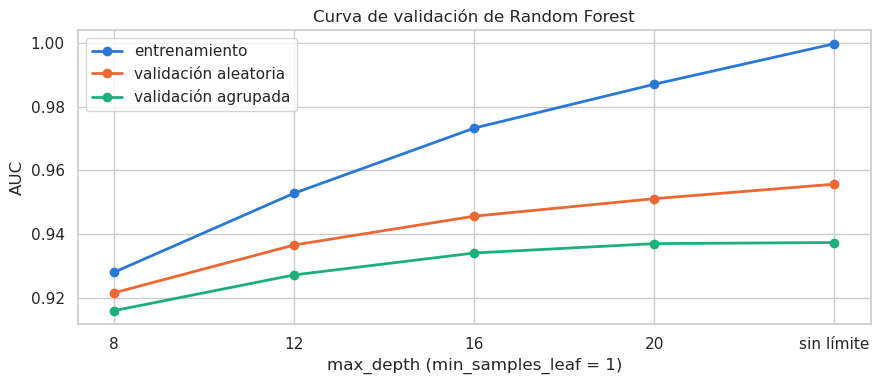

AUC de validación aleatoria menos agrupada, por profundidad:


validacion,aleatoria,agrupada,diferencia
max_depth,,,
8,0.9217,0.9161,0.0056
12,0.9367,0.9273,0.0094
16,0.9457,0.9342,0.0115
20,0.9512,0.9371,0.0141
sin límite,0.9557,0.9374,0.0183


In [20]:
leaf_one = forest_results.loc[forest_results['min_samples_leaf'] == 1]
curves = {
    'entrenamiento': leaf_one.loc[leaf_one['validacion'] == 'aleatoria', 'auc_train'].to_numpy(),
    'validación aleatoria': leaf_one.loc[leaf_one['validacion'] == 'aleatoria', 'auc_val'].to_numpy(),
    'validación agrupada': leaf_one.loc[leaf_one['validacion'] == 'agrupada', 'auc_val'].to_numpy(),
}
colors = {'entrenamiento': BLUE, 'validación aleatoria': '#eb6834', 'validación agrupada': '#1baf7a'}

fig, ax = plt.subplots(figsize=(9, 4))
positions = range(len(DEPTHS))
for name, values in curves.items():
    ax.plot(positions, values, marker='o', linewidth=2, markersize=6, color=colors[name], label=name)
ax.set_xticks(list(positions))
ax.set_xticklabels([depth_label(d) for d in DEPTHS])
ax.set_xlabel('max_depth (min_samples_leaf = 1)')
ax.set_ylabel('AUC')
ax.set_title('Curva de validación de Random Forest')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

gap = (leaf_one.pivot_table(index='max_depth', columns='validacion', values='auc_val', sort=False)
       .assign(diferencia=lambda t: t['aleatoria'] - t['agrupada']))
print('AUC de validación aleatoria menos agrupada, por profundidad:')
display(gap.round(4))

- **Más profundidad es mejor en los dos esquemas.** La AUC de validación aleatoria sube de 0,922 (profundidad 8) a 0,956 (sin límite), y la agrupada también crece hasta 0,937. Hojas de una fila (`min_samples_leaf = 1`) superan a las de cinco en todas las profundidades.
- **El gap con entrenamiento crece mucho** (sin límite, la AUC de entrenamiento es prácticamente 1), pero la validación no empeora. En Random Forest es esperable: cada árbol sobreajusta y el promedio de 300 árboles atenúa sus errores. Lo que decide es la validación.
- **Los duplicados premian memorizar.** La diferencia entre la validación aleatoria y la agrupada crece con la profundidad: un árbol profundo "recuerda" las reservas en lote y acierta sus copias en validación. Aun así, la configuración sin límite también es la mejor con reservas nunca vistas, así que la elección no depende del supuesto sobre el test de la cátedra.

### 6.3 Baseline final

In [21]:
BEST_FOREST = {'max_depth': None, 'min_samples_leaf': 1}
random_forest_rows = forest_results.loc[forest_results['validacion'] == 'aleatoria']
assert random_forest_rows['auc_val'].idxmax() == random_forest_rows.loc[
    (random_forest_rows['max_depth'] == 'sin límite') & (random_forest_rows['min_samples_leaf'] == 1)
].index[0]

baseline_candidates = {
    f'Regresión logística (C = {BEST_C})': logistic_pipeline(BEST_C),
    'Random Forest (sin límite, hoja 1)': forest_pipeline(**BEST_FOREST),
}
comparison_rows = []
for name, model in baseline_candidates.items():
    for scheme in CV_SCHEMES:
        scores = cross_validate_scores(model, X_dev_prep, y_dev, scheme)
        comparison_rows.append({'modelo': name, 'validacion': scheme, **summarize(scores)})
baseline_comparison = pd.DataFrame(comparison_rows).pivot_table(
    index='modelo', columns='validacion', values=['auc_val', 'accuracy_val'], sort=False)
display(baseline_comparison.round(4))

auc_val          accuracy_val         
validacion                         aleatoria agrupada    aleatoria agrupada
modelo                                                                     
Regresión logística (C = 1)           0.9126   0.9075       0.8288   0.8245
Random Forest (sin límite, hoja 1)    0.9557   0.9374       0.8847   0.8568

**Baseline elegido: Random Forest con árboles sin límite de profundidad, hojas de una fila y 300 árboles.**

- Supera a la regresión logística en las dos métricas y en los dos esquemas: 0,043 de AUC y casi 6 puntos de accuracy en la validación aleatoria.
- Frente a la referencia trivial (58,3 %), acierta alrededor del 88 % de las reservas con el umbral 0,5.
- Con reservas nunca vistas (validación agrupada), la estimación baja a una AUC de 0,937 y una accuracy de 0,857. Esa es la cifra prudente para datos nuevos; la aleatoria es la que corresponde al supuesto sobre el Model Score.

### 6.4 Mediciones únicas: leakage y `resource_modifications`

Para comparar dos variantes se usan las diferencias fold a fold con los mismos folds: así la variación entre folds, que afecta igual a las dos, no tapa la diferencia.

In [22]:
def paired_difference(base_scores, variant_scores):
    rows = {}
    for metric in ['auc', 'accuracy']:
        delta = variant_scores[f'test_{metric}'] - base_scores[f'test_{metric}']
        rows[metric] = {'diferencia_media': delta.mean(), 'desvio_entre_folds': delta.std(),
                        'folds_que_mejoran': int((delta > 0).sum())}
    return pd.DataFrame(rows).T


base_scores = cross_validate_scores(forest_pipeline(**BEST_FOREST), X_dev_prep, y_dev, 'aleatoria')

# Benchmark de leakage: se agregan las dos columnas excluidas por su definición.
X_dev_leaky = X_dev_prep.assign(
    assigned_gpu_type=X_dev['assigned_gpu_type'].astype(str),
    queue_wait_time=X_dev['queue_wait_time'].astype(float),
)
leaky_scores = cross_validate_scores(
    forest_pipeline(numeric=NUMERIC_FEATURES + ['queue_wait_time'],
                    categorical=CATEGORICAL_FEATURES + ['assigned_gpu_type'], **BEST_FOREST),
    X_dev_leaky, y_dev, 'aleatoria')
print('Con assigned_gpu_type y queue_wait_time, frente al baseline:')
display(paired_difference(base_scores, leaky_scores).round(4))

# Aporte de resource_modifications: se quita la columna.
without_modifications = [c for c in NUMERIC_FEATURES if c != 'resource_modifications']
ablation_scores = cross_validate_scores(
    forest_pipeline(numeric=without_modifications, **BEST_FOREST),
    X_dev_prep.drop(columns='resource_modifications'), y_dev, 'aleatoria')
print('Sin resource_modifications, frente al baseline:')
display(paired_difference(base_scores, ablation_scores).round(4))

Con assigned_gpu_type y queue_wait_time, frente al baseline:


,diferencia_media,desvio_entre_folds,folds_que_mejoran
auc,0.0014,0.0003,5.0
accuracy,0.0013,0.0015,4.0


Sin resource_modifications, frente al baseline:


,diferencia_media,desvio_entre_folds,folds_que_mejoran
auc,-0.0010,0.0003,0.0
accuracy,-0.0012,0.0017,1.0


- **Leakage:** agregar `assigned_gpu_type` y `queue_wait_time` sube la AUC apenas 0,001 y la accuracy 0,1 puntos (en 4 de los 5 folds). Excluirlas casi no cuesta rendimiento: el resto de las variables ya identifica bien a las reservas que esas columnas marcan. Se confirma la exclusión.
- **`resource_modifications`:** quitarla baja la AUC alrededor de 0,001, de forma consistente en los 5 folds. Su aporte es real pero chico, nada desproporcionado, así que no hay indicios de que cuente cambios posteriores a la predicción. Se conserva.

## 7. Análisis de errores (consigna 3.1)

Se analizan los errores del baseline con sus predicciones *out-of-fold* sobre desarrollo: cada fila se predice con el modelo entrenado en los otros cuatro folds, así que ninguna predicción vio su propia etiqueta. Se usan los mismos folds de la validación cruzada y el umbral 0,5.

El objetivo es encontrar qué tienen en común los errores. Para cada cohorte se responden dos preguntas:

- **Qué parte de los errores cae en la cohorte** (`porcentaje_errores`): cuánto mejoraría el sistema si se resolvieran.
- **Qué proporción de sus filas se clasifica mal** (`error`): qué tan mal funciona el modelo ahí, comparado con el resto.

Como las cohortes tienen tasas de cancelación muy distintas, también se reportan la AUC dentro de la cohorte (no depende de esa tasa ni del umbral), las tasas de falsos positivos y de falsos negativos, y el error con validación agrupada.

In [23]:
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict


@memory.cache
def out_of_fold_proba(model, X, y, scheme):
    cv, groups = CV_SCHEMES[scheme]
    return cross_val_predict(model, X, y, cv=cv, groups=groups, method='predict_proba')[:, 1]


THRESHOLD = 0.5
baseline = forest_pipeline(**BEST_FOREST)

analysis = dev.copy()
analysis['proba'] = out_of_fold_proba(baseline, X_dev_prep, y_dev, 'aleatoria')
analysis['pred'] = (analysis['proba'] >= THRESHOLD).astype(int)
analysis['error'] = analysis['pred'] != analysis[TARGET]
analysis['proba_agrupada'] = out_of_fold_proba(baseline, X_dev_prep, y_dev, 'agrupada')
analysis['error_agrupada'] = (analysis['proba_agrupada'] >= THRESHOLD).astype(int) != analysis[TARGET]
analysis['resultado'] = np.select(
    [analysis['pred'].eq(1) & analysis[TARGET].eq(1), analysis['pred'].eq(0) & analysis[TARGET].eq(1),
     analysis['pred'].eq(0) & analysis[TARGET].eq(0)],
    ['VP', 'FN', 'VN'], default='FP')

# Tamaño del grupo de filas idénticas de cada fila, contado dentro de desarrollo.
dev_keys = pd.Series(groups_dev, index=X_dev.index)
dev_group_size = dev_keys.map(dev_keys.value_counts())
analysis['tamano_lote'] = pd.cut(dev_group_size, [0, 1, 2, 5, 10, 50, np.inf],
                                 labels=['única', '2', '3-5', '6-10', '11-50', 'más de 50'])
analysis['en_lote'] = np.where(dev_group_size > 1, 'en lote', 'única')

oof_auc = roc_auc_score(y_dev, analysis['proba'])
assert abs(oof_auc - base_scores['test_auc'].mean()) < 0.002
global_error = analysis['error'].mean()
print(f'AUC out-of-fold: {oof_auc:.4f}. Accuracy: {1 - global_error:.4f}. '
      f"Errores: {analysis['error'].sum()} de {len(analysis)} filas.")
display(pd.DataFrame(confusion_matrix(y_dev, analysis['pred']),
                     index=['real: se ejecuta', 'real: se cancela'],
                     columns=['predicho: se ejecuta', 'predicho: se cancela']))
print(f"Tasa de falsos positivos: {analysis.loc[y_dev.eq(0), 'pred'].mean():.1%} de las que se ejecutan")
print(f"Tasa de falsos negativos: {1 - analysis.loc[y_dev.eq(1), 'pred'].mean():.1%} de las canceladas")

# En un grupo de filas idénticas con etiquetas mezcladas, la etiqueta minoritaria se predice mal siempre.
labels_by_group = analysis.groupby(dev_keys)[TARGET].agg(['size', 'sum'])
unavoidable = np.minimum(labels_by_group['sum'], labels_by_group['size'] - labels_by_group['sum']).sum()
print(f'Errores inevitables por filas idénticas con etiquetas distintas: {unavoidable} '
      f'({unavoidable / len(analysis):.1%} de desarrollo)')

AUC out-of-fold: 0.9557. Accuracy: 0.8844. Errores: 4423 de 38273 filas.


,predicho: se ejecuta,predicho: se cancela
real: se ejecuta,20713,1596
real: se cancela,2827,13137


Tasa de falsos positivos: 7.2% de las que se ejecutan
Tasa de falsos negativos: 17.7% de las canceladas
Errores inevitables por filas idénticas con etiquetas distintas: 113 (0.3% de desarrollo)


- La AUC (0,956) y la accuracy (0,884) *out-of-fold* coinciden con las de la validación cruzada del baseline: son las mismas predicciones.
- Hay 4.423 errores:
  - **2.827 son falsos negativos:** el modelo no anticipa el 17,7 % de las cancelaciones.
  - **1.596 son falsos positivos:** marca como cancelación el 7,2 % de las reservas que se ejecutan.
  - Con el umbral 0,5, el modelo se equivoca más por no detectar cancelaciones.
- Sólo 113 errores (0,3 % de desarrollo) son inevitables, porque hay filas idénticas con etiquetas distintas. Es una cota inferior del error irreducible: no capta las filas parecidas, pero no idénticas, que tienen etiquetas distintas. En datos tabulares no hay un rendimiento humano de referencia (HLP) que dé una cota mejor.

### 7.1 Cohortes

Se muestran las cohortes con al menos 50 filas; las más chicas tienen métricas demasiado ruidosas.

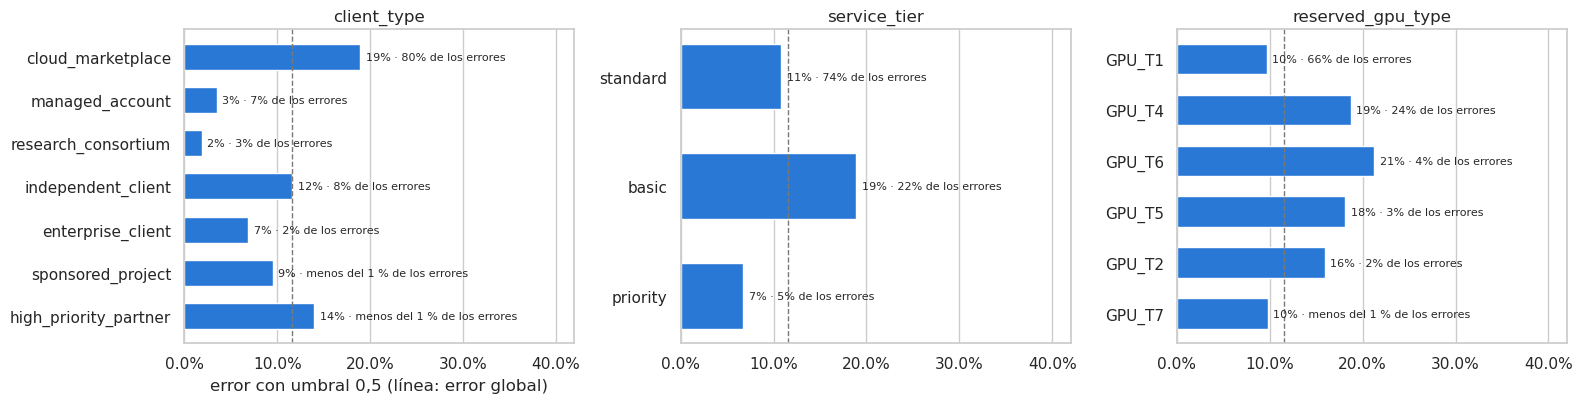

In [24]:
ERROR_COLUMNS = [TARGET, 'pred', 'proba', 'error', 'error_agrupada']
ERROR_FORMAT = {
    'filas': '{:.0f}', 'porcentaje_filas': '{:.1%}', 'tasa_cancelacion': '{:.1%}', 'error': '{:.1%}',
    'porcentaje_errores': '{:.1%}', 'tasa_fp': '{:.1%}', 'tasa_fn': '{:.1%}', 'auc': '{:.3f}',
    'error_agrupada': '{:.1%}',
}


def error_metrics(group, frame):
    canceled = group[TARGET].eq(1)
    return pd.Series({
        'filas': len(group),
        'porcentaje_filas': len(group) / len(frame),
        'tasa_cancelacion': canceled.mean(),
        'error': group['error'].mean(),
        'porcentaje_errores': group['error'].sum() / frame['error'].sum(),
        'tasa_fp': group.loc[~canceled, 'pred'].mean(),
        'tasa_fn': 1 - group.loc[canceled, 'pred'].mean(),
        'auc': roc_auc_score(group[TARGET], group['proba']) if canceled.nunique() == 2 else np.nan,
        'error_agrupada': group['error_agrupada'].mean(),
    })


def error_table(by, frame=None, sort=True):
    # `porcentaje_errores` es la parte de los errores de `frame` que cae en cada cohorte.
    frame = analysis if frame is None else frame
    table = (frame.groupby(by, dropna=False, observed=True)[ERROR_COLUMNS]
             .apply(error_metrics, frame=frame))
    table = table.loc[table['filas'] >= MIN_CATEGORY_ROWS]
    return table.sort_values('filas', ascending=False) if sort else table


def show_errors(table):
    display(table.style.format(ERROR_FORMAT, na_rep='—'))


def plot_errors(ax, table, title):
    # Barras con el error de cada cohorte; la línea marca el error global.
    table = table.iloc[::-1]
    ax.barh(table.index.astype(str), table['error'], color=BLUE, height=0.6)
    ax.axvline(global_error, color=REFERENCE, linestyle='--', linewidth=1)
    for position, (error, share) in enumerate(zip(table['error'], table['porcentaje_errores'])):
        share_label = f'{share:.0%}' if share >= 0.01 else 'menos del 1 %'
        ax.text(error + 0.006, position, f'{error:.0%} · {share_label} de los errores', va='center', fontsize=8)
    ax.set_xlim(0, 0.42)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(title)
    ax.grid(axis='y', visible=False)


required_cohorts = {column: error_table(column) for column in ['client_type', 'service_tier', 'reserved_gpu_type']}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (column, table) in zip(axes, required_cohorts.items()):
    plot_errors(ax, table, column)
axes[0].set_xlabel('error con umbral 0,5 (línea: error global)')
plt.tight_layout()
plt.show()

show_errors(pd.concat(required_cohorts, names=['variable', 'cohorte']))

- **`client_type` concentra los errores.** `cloud_marketplace` tiene el 49 % de las filas y el 80 % de los errores. Se equivoca en el 19 % de sus reservas, contra 3,5 % en `managed_account` y 1,8 % en `research_consortium`. Su AUC interna (0,89) es la más baja entre las cohortes grandes.
- **Tasa alta no significa cohorte difícil.** `research_consortium` es la cohorte que más se cancela (67 %) y la que mejor se predice (AUC 0,997), porque sus cancelaciones son, sobre todo, `locked_allocation` o lotes.
- **Las cohortes que casi no se cancelan esconden falsos negativos.** `independent_client`, `sponsored_project` y `high_priority_partner` tienen un error moderado, porque predecir "se ejecuta" casi siempre acierta. Pero el modelo no anticipa entre el 67 % y el 92 % de sus cancelaciones, y su AUC interna es la más baja (0,64 a 0,83).
- **`service_tier`:** `basic` tiene 19 % de error, contra 11 % de `standard` y 7 % de `priority`. Explica el 22 % de los errores con el 13 % de las filas.
- **`reserved_gpu_type`:** `GPU_T4` tiene 19 % de error, contra 10 % de `GPU_T1`. Explica el 24 % de los errores con el 15 % de las filas. Las GPU menos frecuentes van del 10 % al 21 %.
- **Validación agrupada:** el orden de las cohortes se mantiene. El error sube más en las cohortes con muchos lotes; por ejemplo, `research_consortium` pasa de 1,8 % a 5,0 %.

In [25]:
# ¿basic y GPU_T4 son difíciles por sí mismas o porque son, sobre todo, cloud_marketplace?
client_group = analysis['client_type'].where(analysis['client_type'].eq('cloud_marketplace'), 'otros clientes')
for column in ['service_tier', 'reserved_gpu_type']:
    frequent = analysis[column].map(analysis[column].value_counts()).ge(MIN_CATEGORY_ROWS)
    share = pd.crosstab(analysis.loc[frequent, column], client_group[frequent], normalize='index')
    error_by_group = pd.crosstab(analysis.loc[frequent, column], client_group[frequent],
                                 values=analysis.loc[frequent, 'error'], aggfunc='mean')
    composition = pd.concat({'porcentaje de filas': share, 'error': error_by_group}, axis=1)
    display(composition.style.format('{:.1%}', na_rep='—'))

`basic` y `GPU_T4` son, sobre todo, reservas de `cloud_marketplace` (93 % y 79 %).

- Dentro de `cloud_marketplace`, `basic` y `standard` tienen casi el mismo error (19,5 % y 18,6 %). `GPU_T4` queda algo por encima de `GPU_T1` (21,4 % y 17,9 %).
- Fuera de `cloud_marketplace`, `basic` sigue siendo peor que `standard` (11,1 % y 4,7 %), pero son sólo 341 filas.

**Conclusión:** casi toda la diferencia de estas dos cohortes viene de su composición: heredan el error de `cloud_marketplace`. Mejorar esa cohorte las mejora también, porque comparten la mayoría de sus filas.

In [26]:
lead_quintiles = pd.qcut(analysis['hours_before_execution'], 5).cat.rename_categories(
    lambda i: f'{0 if i.left < 0 else int(i.left) + 1}–{int(i.right)} h')
other_cohorts = {
    'reservation_commitment': error_table('reservation_commitment'),
    'tamaño del lote': error_table('tamano_lote', sort=False),
    'request_channel': error_table('request_channel'),
    'anticipación (quintiles)': error_table(lead_quintiles, sort=False),
    'costo por hora': error_table(analysis['estimated_cost_per_hour'].eq(0).map({True: 'igual a 0', False: 'mayor que 0'})),
}
show_errors(pd.concat(other_cohorts, names=['variable', 'cohorte']))

- **`reservation_commitment`:** con `locked_allocation` el modelo casi no se equivoca (0,1 %). El 99,8 % de los errores está en `no_commitment`.
- **Lotes:** las reservas únicas son el 61 % de las filas y el 94 % de los errores.
  - En los lotes, el error es bajo con validación aleatoria (0,5 % a 5 %) pero sube con la agrupada (4 % a 17 %). Los aciertos en lotes dependen en buena parte de haber visto una gemela en entrenamiento.
  - El caso más claro son los pares: 5,3 % de error con validación aleatoria y 17,2 % con la agrupada, el mismo nivel que las reservas únicas.
- **`request_channel`:** `api_direct` repite el patrón de las cohortes que casi no se cancelan. Tiene 11 % de error, pero el 61 % de sus cancelaciones pasa sin aviso.
- **Anticipación:**
  - El quintil de menor anticipación (hasta 15 horas) casi no se cancela (17 %), y el modelo no anticipa la mitad de sus cancelaciones.
  - El error más alto está entre 16 y 50 horas (15 %).
  - Desde 185 horas, las cancelaciones son mayoría y el modelo las reconoce bien: el error baja a 7 % y la AUC sube a 0,985.
- **Costo 0:** tiene una AUC interna de 0,76 y 75 % de falsos negativos. Pero son 578 filas y el 1,2 % de los errores, así que no es prioritario.

### 7.2 Regiones problemáticas

Las tablas anteriores apuntan a dos factores: el tipo de cliente y si la reserva es parte de un lote. Se cruzan para ubicar la región donde se concentran los errores, y después se busca si dentro de esa región hay un subgrupo todavía peor.

In [27]:
regions = error_table(['client_type', 'en_lote'])
show_errors(regions)

marketplace_single = analysis['client_type'].eq('cloud_marketplace') & analysis['en_lote'].eq('única')
region = analysis.loc[marketplace_single]
region_lead = pd.qcut(region['hours_before_execution'], 5).cat.rename_categories(
    lambda i: f'{0 if i.left < 0 else int(i.left) + 1}–{int(i.right)} h')
top_regions = region['client_region'].value_counts().index[:5]
inside_region = {
    'anticipación (quintiles)': error_table(region_lead, frame=region, sort=False),
    'service_tier': error_table('service_tier', frame=region),
    'reserved_gpu_type': error_table('reserved_gpu_type', frame=region),
    'special_resource_requests': error_table(region['special_resource_requests'].clip(upper=3)
                                             .map(lambda v: '3 o más' if v == 3 else str(v)), frame=region),
    'client_region (5 principales)': error_table(region['client_region'].where(
        region['client_region'].isin(top_regions), 'otras'), frame=region),
}
print('Dentro de cloud_marketplace sin lote (porcentaje_errores: parte de los errores de la región):')
show_errors(pd.concat(inside_region, names=['variable', 'cohorte']))

print('Información sobre el cliente y probabilidades dudosas, dentro y fuera de la región:')
history = pd.DataFrame({
    'previous_job_cancellations > 0': analysis['previous_job_cancellations'].gt(0),
    'successful_previous_jobs > 0': analysis['successful_previous_jobs'].gt(0),
    'returning_client = 1': analysis['returning_client'].eq(1),
    'con organization_id': analysis['organization_id'].notna(),
    'probabilidad entre 0,3 y 0,7': analysis['proba'].between(0.3, 0.7),
    'error': analysis['error'],
}).groupby(np.where(marketplace_single, 'cloud_marketplace sin lote', 'resto')).mean().T
display(history.style.format('{:.1%}'))

Dentro de cloud_marketplace sin lote (porcentaje_errores: parte de los errores de la región):


Información sobre el cliente y probabilidades dudosas, dentro y fuera de la región:


,cloud_marketplace sin lote,resto
previous_job_cancellations > 0,0.9%,10.9%
successful_previous_jobs > 0,0.4%,3.3%
returning_client = 1,0.5%,3.9%
con organization_id,0.2%,8.2%
"probabilidad entre 0,3 y 0,7",37.9%,5.8%
error,21.4%,4.6%


**Región problemática: las reservas individuales de `cloud_marketplace`** (sin gemelas en desarrollo).

- Son el 41 % de las filas y concentran el 77 % de los errores. Su error es 21,4 %, contra 4,6 % en el resto, y su AUC interna es 0,86. Con validación agrupada el error es el mismo (21,5 %): acá no hay memorización que ayude.
- **Ningún subgrupo se separa dentro de la región.** Por tier, GPU y región del cliente, el error va de 19 % a 25 % en todos los subgrupos grandes. Por anticipación crece de 13 % a 25 %. El quintil de menor anticipación tiene menos error sólo porque casi no se cancela.
- **El modelo se apoya en `special_resource_requests`:**
  - Sin pedidos especiales, predice muchas cancelaciones que no ocurren (35 % de falsos positivos).
  - Con uno o más, deja pasar entre el 64 % y el 83 % de las cancelaciones.
  - Es la señal más fuerte que tiene en la región, pero no alcanza.
- **Faltan datos del cliente.** En la región casi ninguna reserva tiene historial:
  - 0,9 % tiene cancelaciones previas;
  - 0,4 % tiene trabajos previos exitosos;
  - 0,5 % son clientes que vuelven;
  - 0,2 % tiene organización.

  En el resto, esos porcentajes van de 3 % a 11 %.
- El 38 % de las predicciones de la región está entre 0,3 y 0,7, contra el 6 % en el resto.

**Inferencia:** el modelo no falla por un patrón que se le escape. Las reservas individuales que llegan por el marketplace no traen información sobre el cliente, y lo que se registra de la reserva no alcanza para distinguir a quienes van a cancelar.

### 7.3 Falsos positivos y falsos negativos

Se mira con qué confianza se equivoca el modelo y en qué se parecen los errores a los aciertos.

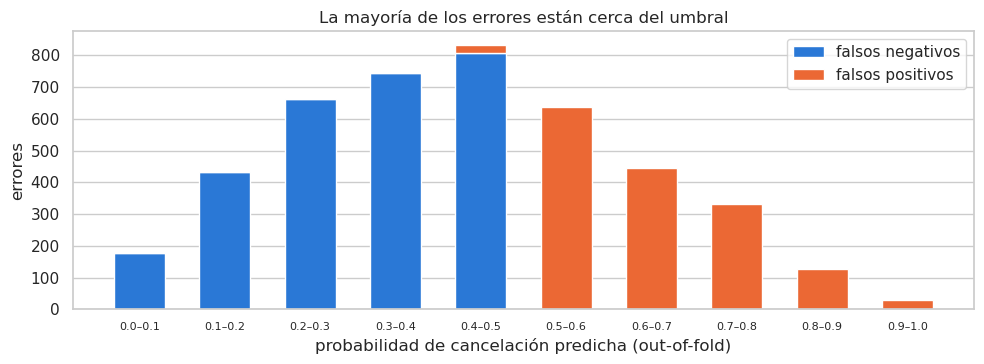

,filas,tasa_cancelacion_observada,falsos_negativos,falsos_positivos,porcentaje_errores
proba,,,,,
"(-0.001, 0.1]",12238,1.5%,178,0,4.0%
"(0.1, 0.2]",4263,10.1%,432,0,9.8%
"(0.2, 0.3]",2961,22.4%,664,0,15.0%
"(0.3, 0.4]",2296,32.4%,745,0,16.8%
"(0.4, 0.5]",1822,45.1%,808,26,18.9%
"(0.5, 0.6]",1575,59.6%,0,637,14.4%
"(0.6, 0.7]",1560,71.5%,0,444,10.0%
"(0.7, 0.8]",1655,80.0%,0,331,7.5%
"(0.8, 0.9]",1368,90.6%,0,128,2.9%


Errores con probabilidad entre 0,3 y 0,7: 61%


In [28]:
probability_bins = pd.cut(analysis['proba'], np.linspace(0, 1, 11), include_lowest=True)
by_probability = analysis.groupby(probability_bins, observed=True).agg(
    filas=('error', 'size'), tasa_cancelacion_observada=(TARGET, 'mean'),
    falsos_negativos=('resultado', lambda r: r.eq('FN').sum()),
    falsos_positivos=('resultado', lambda r: r.eq('FP').sum()))
bin_errors = by_probability['falsos_negativos'] + by_probability['falsos_positivos']
by_probability['porcentaje_errores'] = bin_errors / bin_errors.sum()

positions = range(len(by_probability))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(positions, by_probability['falsos_negativos'], color=BLUE, width=0.6, label='falsos negativos')
ax.bar(positions, by_probability['falsos_positivos'], bottom=by_probability['falsos_negativos'],
       color='#eb6834', width=0.6, label='falsos positivos')
ax.set_xticks(list(positions))
ax.set_xticklabels([f'{max(i.left, 0):.1f}–{i.right:.1f}' for i in by_probability.index], fontsize=8)
ax.set_xlabel('probabilidad de cancelación predicha (out-of-fold)')
ax.set_ylabel('errores')
ax.set_title('La mayoría de los errores están cerca del umbral')
ax.legend(loc='upper right')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

display(by_probability.style.format({'tasa_cancelacion_observada': '{:.1%}', 'porcentaje_errores': '{:.1%}'}))
near_threshold = analysis.loc[analysis['error'], 'proba'].between(0.3, 0.7).mean()
print(f'Errores con probabilidad entre 0,3 y 0,7: {near_threshold:.0%}')

- **Los errores son, sobre todo, casos dudosos.** El 61 % tiene una probabilidad predicha entre 0,3 y 0,7. Hay pocos errores "seguros": 178 falsos negativos con probabilidad menor que 0,1 y 30 falsos positivos con probabilidad mayor que 0,9.
- **Los falsos negativos están más dispersos.** Muchos tienen probabilidades de 0,1 a 0,3: son cancelaciones que el modelo veía poco probables, no casos en el límite.
- **Las probabilidades están calibradas.** En cada intervalo, la tasa observada de cancelación cae dentro del intervalo o muy cerca (por ejemplo, 59,6 % entre 0,5 y 0,6). Una probabilidad de 0,7 significa que, aproximadamente, 7 de cada 10 reservas así se cancelan. Esto se usa en 7.4.

In [29]:
profile_flags = pd.DataFrame({
    'cloud_marketplace': analysis['client_type'].eq('cloud_marketplace'),
    'reserva única (sin lote)': analysis['en_lote'].eq('única'),
    'locked_allocation': analysis['reservation_commitment'].eq('locked_allocation'),
    'previous_job_cancellations > 0': analysis['previous_job_cancellations'].gt(0),
    'special_resource_requests > 0': analysis['special_resource_requests'].gt(0),
    'resource_modifications > 0': analysis['resource_modifications'].gt(0),
    'client_region = PRT': analysis['client_region'].eq('PRT'),
    'request_channel = broker_platform': analysis['request_channel'].eq('broker_platform'),
})
OUTCOME_ORDER = ['VP', 'FN', 'VN', 'FP']
profile = profile_flags.groupby(analysis['resultado']).mean().T[OUTCOME_ORDER]
lead_median = analysis.groupby('resultado')['hours_before_execution'].median()[OUTCOME_ORDER]
counts = analysis['resultado'].value_counts()[OUTCOME_ORDER]
print('Filas por resultado:', counts.to_dict())
print('Proporción de filas con cada característica, por resultado '
      '(VP y FN son canceladas; VN y FP, ejecutadas):')
display(profile.style.format('{:.0%}'))
print('Mediana de hours_before_execution:', lead_median.to_dict())

Filas por resultado: {'VP': 13137, 'FN': 2827, 'VN': 20713, 'FP': 1596}
Proporción de filas con cada característica, por resultado (VP y FN son canceladas; VN y FP, ejecutadas):


resultado,VP,FN,VN,FP
cloud_marketplace,38%,74%,49%,90%
reserva única (sin lote),31%,93%,73%,94%
locked_allocation,48%,0%,0%,0%
previous_job_cancellations > 0,18%,1%,1%,0%
special_resource_requests > 0,11%,66%,55%,30%
resource_modifications > 0,4%,14%,19%,7%
client_region = PRT,67%,30%,24%,18%
request_channel = broker_platform,97%,84%,81%,98%


Mediana de hours_before_execution: {'VP': 132.0, 'FN': 52.0, 'VN': 47.0, 'FP': 77.0}


- **Los falsos negativos se parecen a las reservas que se ejecutan.**
  - El 93 % son reservas únicas, y casi ninguno tiene cancelaciones previas ni `locked_allocation`.
  - El 66 % pidió recursos especiales, como el 55 % de los VN (en los VP, sólo el 11 %).
  - Su anticipación mediana (52 horas) es casi la de los VN (47).
  - No tienen ninguna de las señales fuertes de cancelación.
- **Los falsos positivos tienen el perfil de riesgo de `cloud_marketplace`.**
  - El 90 % es de ese cliente y el 98 % entra por `broker_platform`.
  - Piden menos recursos especiales (30 %) y reservan con más anticipación (77 horas) que los VN.
  - Se parecen a las canceladas, pero se ejecutaron.
- **Conclusión:** los errores no están en una zona que el modelo trate mal por falta de capacidad. Son reservas cuyas variables registradas se parecen a las de la clase contraria. Para separarlas hace falta información que hoy no está en los datos.

### 7.4 Si los errores no cuestan lo mismo

La accuracy supone que un falso positivo y un falso negativo cuestan lo mismo. En la operación de la plataforma no es así:

- Un **falso positivo** anticipa una cancelación que no ocurre. Si la plataforma reasigna esa GPU, el cliente llega y no tiene recursos.
- Un **falso negativo** no anticipa una cancelación. La GPU queda reservada y ociosa.

No hay datos para fijar la proporción entre los dos costos, así que se muestran tres escenarios. Si las probabilidades están calibradas, conviene predecir "se cancela" cuando `p > c_FP / (c_FP + c_FN)`. La tabla de 7.3 muestra que las probabilidades *out-of-fold* del baseline están razonablemente calibradas (la tasa observada en cada intervalo cae dentro del intervalo o muy cerca), así que se compara ese umbral teórico con el que minimiza el costo en desarrollo.

Es un análisis del baseline. El umbral del predictor final se elige en el paso 5 con las predicciones *out-of-fold* del modelo final.

In [30]:
def cost_scenarios(y_true, proba, ratios=(1, 2, 3)):
    y_true = np.asarray(y_true)
    thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
    false_positives = np.array([((proba >= t) & (y_true == 0)).sum() for t in thresholds])
    false_negatives = np.array([((proba < t) & (y_true == 1)).sum() for t in thresholds])
    rows = []
    for ratio in ratios:
        best = int(np.argmin(ratio * false_positives + false_negatives))
        fp, fn = false_positives[best], false_negatives[best]
        predicted_positive = (proba >= thresholds[best]).sum()
        rows.append({
            'costo FP : FN': f'{ratio} : 1',
            'umbral_teorico': ratio / (ratio + 1),
            'umbral_optimo_dev': thresholds[best],
            'falsos_positivos': fp,
            'falsos_negativos': fn,
            'accuracy': 1 - (fp + fn) / len(y_true),
            'recall': 1 - fn / (y_true == 1).sum(),
            'especificidad': 1 - fp / (y_true == 0).sum(),
            'precision': (predicted_positive - fp) / predicted_positive,
        })
    return pd.DataFrame(rows).set_index('costo FP : FN')


scenarios = cost_scenarios(y_dev, analysis['proba'].to_numpy())
display(scenarios.style.format({
    'umbral_teorico': '{:.2f}', 'umbral_optimo_dev': '{:.2f}', 'accuracy': '{:.3f}',
    'recall': '{:.1%}', 'especificidad': '{:.1%}', 'precision': '{:.1%}'}))

,umbral_teorico,umbral_optimo_dev,falsos_positivos,falsos_negativos,accuracy,recall,especificidad,precision
costo FP : FN,,,,,,,,
1 : 1,0.50,0.48,1757,2650,0.885,83.4%,92.1%,88.3%
2 : 1,0.67,0.62,842,3955,0.875,75.2%,96.2%,93.4%
3 : 1,0.75,0.68,568,4620,0.864,71.1%,97.5%,95.2%


- **Con costos iguales, el umbral 0,5 ya es el óptimo.** El mejor en desarrollo es 0,48, y mejora la accuracy en una décima (0,885 contra 0,884). Para la competencia no hace falta moverlo.
- **Si un falso positivo cuesta el doble,** conviene subir el umbral a alrededor de 0,62.
  - Los falsos positivos bajan a la mitad (de 1.596 a 842).
  - Los falsos negativos suben de 2.827 a 3.955.
  - La accuracy baja un punto, pero ocurre el 93 % de las cancelaciones anunciadas.
- **Si cuesta el triple,** el umbral sube a 0,68. Sólo el 2,5 % de las reservas que se ejecutan se marca como cancelación, y se anticipa el 71 % de las cancelaciones.
- **Umbrales óptimos y teóricos:** los óptimos quedan algo por debajo de los teóricos (0,62 contra 0,67 y 0,68 contra 0,75). Cerca del óptimo el costo cambia poco: usar el umbral teórico costaría menos de un 2 % más.
- **Decisión:** el modelo se elige por AUC y accuracy, sin fijar costos. El umbral es una decisión operativa que se puede cambiar sin reentrenar: si la plataforma define cuánto cuesta cada error, alcanza con moverlo.

## 8. Curvas de aprendizaje (consigna 3.2)

Se entrena el baseline con fracciones crecientes de cada fold de entrenamiento (10 %, 25 %, 50 %, 75 % y 100 %) y se evalúa siempre en el fold de validación completo. Si la validación sigue subiendo al agregar datos, más datos ayudarían; si ya se aplanó, el límite está en el modelo o en la información de las variables.

Con validación aleatoria hay un efecto extra: al crecer el entrenamiento, también crece la probabilidad de que una fila de validación tenga una gemela en entrenamiento. La curva agrupada no tiene ese efecto, así que mide mejor cuánto ayudan más reservas nuevas.

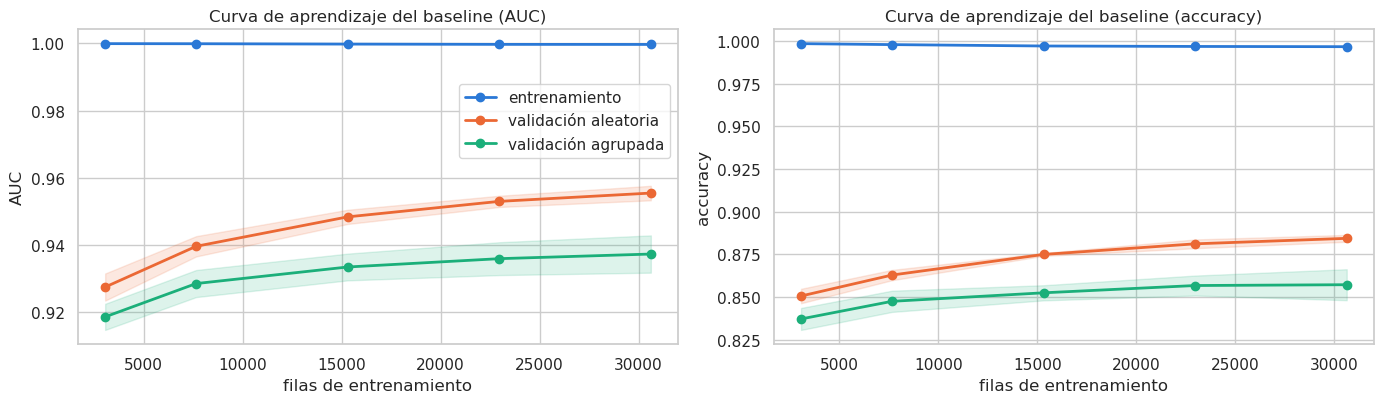

In [31]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score

TRAIN_FRACTIONS = (0.1, 0.25, 0.5, 0.75, 1.0)


@memory.cache
def learning_curve_scores(model, X, y, scheme, fractions):
    # Cada fracción toma las primeras filas de una misma permutación del fold de entrenamiento.
    cv, groups = CV_SCHEMES[scheme]
    rows = []
    for fold, (train, validation) in enumerate(cv.split(X, y, groups)):
        order = np.random.RandomState(RANDOM_STATE).permutation(train)
        for fraction in fractions:
            subset = order[:int(round(fraction * len(train)))]
            fitted = clone(model).fit(X.iloc[subset], y.iloc[subset])
            row = {'validacion': scheme, 'fold': fold, 'fraccion': fraction, 'filas_entrenamiento': len(subset)}
            for part, indices in [('train', subset), ('val', validation)]:
                proba = fitted.predict_proba(X.iloc[indices])[:, 1]
                row[f'auc_{part}'] = roc_auc_score(y.iloc[indices], proba)
                row[f'accuracy_{part}'] = accuracy_score(y.iloc[indices], proba >= THRESHOLD)
            rows.append(row)
    return pd.DataFrame(rows)


learning = pd.concat([learning_curve_scores(baseline, X_dev_prep, y_dev, scheme, TRAIN_FRACTIONS)
                      for scheme in CV_SCHEMES])
learning_mean = learning.groupby(['validacion', 'fraccion']).mean(numeric_only=True)
learning_std = learning.groupby(['validacion', 'fraccion']).std(numeric_only=True)

series = {
    'entrenamiento': ('aleatoria', 'train', BLUE),
    'validación aleatoria': ('aleatoria', 'val', '#eb6834'),
    'validación agrupada': ('agrupada', 'val', '#1baf7a'),
}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, metric in zip(axes, ['auc', 'accuracy']):
    for name, (scheme, part, color) in series.items():
        mean = learning_mean.loc[scheme]
        values = mean[f'{metric}_{part}']
        ax.plot(mean['filas_entrenamiento'], values, marker='o', linewidth=2, markersize=6, color=color, label=name)
        if part == 'val':
            spread = learning_std.loc[scheme, f'{metric}_{part}']
            ax.fill_between(mean['filas_entrenamiento'], values - spread, values + spread, color=color, alpha=0.15)
    ax.set_xlabel('filas de entrenamiento')
    ax.set_ylabel(metric.upper() if metric == 'auc' else 'accuracy')
    ax.set_title(f'Curva de aprendizaje del baseline ({"AUC" if metric == "auc" else "accuracy"})')
axes[0].legend(loc='upper right', bbox_to_anchor=(1, 0.85))
plt.tight_layout()
plt.show()

summary = learning_mean[['filas_entrenamiento', 'auc_val', 'accuracy_val']].unstack('validacion')
summary.index = [f'{fraction:.0%}' for fraction in summary.index]
summary.index.name = 'fracción del fold'
display(summary.style.format({c: '{:.0f}' if c[0] == 'filas_entrenamiento' else '{:.4f}' for c in summary.columns}))

- **Entrenamiento:** la AUC es prácticamente 1 con cualquier cantidad de filas. El modelo puede ajustar todo lo que ve: no le falta capacidad.
- **Validación agrupada (reservas nuevas):** sube rápido al principio y después casi se aplana. Pasa de 0,919 con 3.000 filas a 0,933 con 15.300 y a 0,937 con 30.600. El último 25 % de los datos sumó 0,0014 de AUC y 0,0005 de accuracy, menos que el desvío entre folds (alrededor de 0,005).
- **Validación aleatoria:** sube más, de 0,948 a 0,956 entre la mitad de las filas y el total, porque con más entrenamiento también hay más gemelas de las filas de validación. Parte de esa mejora es memorización de lotes, no aprendizaje sobre reservas nuevas.
- **La brecha con entrenamiento es grande** (0,044 de AUC con validación aleatoria y 0,062 con la agrupada). Una brecha grande con una validación que sigue subiendo suele indicar que más datos ayudarían. Acá la brecha es estructural: un Random Forest sin límite de profundidad siempre memoriza el entrenamiento (sección 6.2). Lo que decide es la pendiente de la validación, y es baja.

**Diagnóstico.** **Inferencia:** el sistema no está limitado por la cantidad de filas, sino por la información que traen las variables.

- Al duplicar las filas de 15.300 a 30.600, la AUC agrupada subió 0,004. Si la tendencia se mantiene, otra duplicación sumaría unas milésimas.
- Coincide con el análisis de errores: son casos dudosos, sin señales que los distingan.
- Más filas del mismo tipo ayudarían poco. Lo que más puede ayudar es agregar información, con variables derivadas o con datos nuevos: agregar variables también es una forma de agregar datos.
- En el paso 4 se prueba además si un modelo con otro sesgo, como gradient boosting, extrae más de las mismas variables.

**Para el paso 5:** con el supuesto de que el Model Score se mide sobre el mismo conjunto de reservas, entrenar el predictor final con más filas sí suma algo, porque la curva aleatoria sigue subiendo. Se propone reentrenarlo con desarrollo y test juntos después de la evaluación única en test. Se decide en ese paso.

## 9. Estrategia data-centered (consigna 3.3)

**Cohorte elegida: las reservas individuales de `cloud_marketplace`** (sin gemelas en desarrollo), la región problemática de 7.2.

Un enfoque centrado en los datos deja fijo un modelo que funciona razonablemente bien y trabaja sobre la cantidad, la calidad o la información de los datos. Para elegir dónde intervenir se usan cuatro criterios:

- cuánto margen de mejora hay;
- con qué frecuencia aparece la cohorte;
- qué tan fácil es mejorarla;
- qué tan importante es.

Las otras dos candidatas eran los clientes directos que casi no cancelan y los lotes nunca vistos. Quedan como siguientes pasos.

### 9.1 Frecuencia e impacto operativo

In [32]:
region_mask = marketplace_single
total_by_outcome = analysis['resultado'].value_counts()
impact_rows = {}
for name, mask in [('cloud_marketplace sin lote', region_mask), ('resto', ~region_mask)]:
    part = analysis.loc[mask]
    outcome = part['resultado'].value_counts()
    impact_rows[name] = {
        'filas': len(part),
        'porcentaje_filas': len(part) / len(analysis),
        'errores': part['error'].sum(),
        'porcentaje_errores': part['error'].sum() / analysis['error'].sum(),
        'falsos_negativos': outcome.get('FN', 0),
        'porcentaje_fn': outcome.get('FN', 0) / total_by_outcome['FN'],
        'falsos_positivos': outcome.get('FP', 0),
        'porcentaje_fp': outcome.get('FP', 0) / total_by_outcome['FP'],
        'error': part['error'].mean(),
        'auc': roc_auc_score(part[TARGET], part['proba']),
        'error_agrupada': part['error_agrupada'].mean(),
    }
impact = pd.DataFrame(impact_rows).T
display(impact.style.format({
    'filas': '{:.0f}', 'errores': '{:.0f}', 'falsos_negativos': '{:.0f}', 'falsos_positivos': '{:.0f}',
    'porcentaje_filas': '{:.1%}', 'porcentaje_errores': '{:.1%}', 'porcentaje_fn': '{:.1%}',
    'porcentaje_fp': '{:.1%}', 'error': '{:.1%}', 'auc': '{:.3f}', 'error_agrupada': '{:.1%}'}))

print('Compromiso de las reservas de la región:')
display(analysis.loc[region_mask, 'reservation_commitment'].value_counts(normalize=True)
        .to_frame('porcentaje').style.format('{:.2%}'))
print(f'Cada punto de error que baje en la región suma {region_mask.mean():.2f} puntos de accuracy global.')

,filas,porcentaje_filas,errores,porcentaje_errores,falsos_negativos,porcentaje_fn,falsos_positivos,porcentaje_fp,error,auc,error_agrupada
cloud_marketplace sin lote,15855,41.4%,3393,76.7%,2002,70.8%,1391,87.2%,21.4%,0.860,21.5%
resto,22418,58.6%,1030,23.3%,825,29.2%,205,12.8%,4.6%,0.988,9.2%


Compromiso de las reservas de la región:


,porcentaje
reservation_commitment,
no_commitment,99.96%
locked_allocation,0.03%
flexible_commitment,0.02%


Cada punto de error que baje en la región suma 0.41 puntos de accuracy global.


- **Frecuencia:** son 15.855 reservas, el 41 % de desarrollo. Casi todas son `no_commitment` (99,96 %). Por definición, no tienen ninguna de las dos señales más fuertes del dataset: el compromiso `locked_allocation` y el lote.
- **Margen de mejora:**
  - El error es 21,4 %, contra 4,6 % en el resto, y la AUC es 0,86, contra 0,99.
  - Concentra 3.393 de los 4.423 errores.
  - Cada punto de error que baje en la región suma 0,41 puntos de accuracy global.
- **Impacto operativo:**
  - **2.002 falsos negativos (71 % de todos):** reservas que se cancelan sin aviso y dejan GPUs reservadas ociosas.
  - **1.391 falsos positivos (87 % de todos):** reservas que se ejecutan pero se habrían marcado como cancelación. Si la plataforma reasignara esas GPUs, el cliente llegaría y no tendría recursos.
  - `cloud_marketplace` es el principal origen de reservas (49 %), así que es donde una mejora más se nota en la operación.
- **Importancia:** el error no depende de memorizar lotes (21,5 % con validación agrupada), así que una mejora también valdría para reservas nuevas.

### 9.2 Posibles causas

En 7.2 y 7.3 ya se vio que en la región casi no hay historial del cliente y que los errores son casos dudosos. Acá se descartan otras dos explicaciones posibles:

- **Que falten filas de este tipo.** Se recalcula la curva de aprendizaje del baseline midiendo sólo las filas de validación de la región. Se usa validación aleatoria, porque las filas de la región no tienen gemelas.
- **Que el umbral no sea el adecuado para la región.**

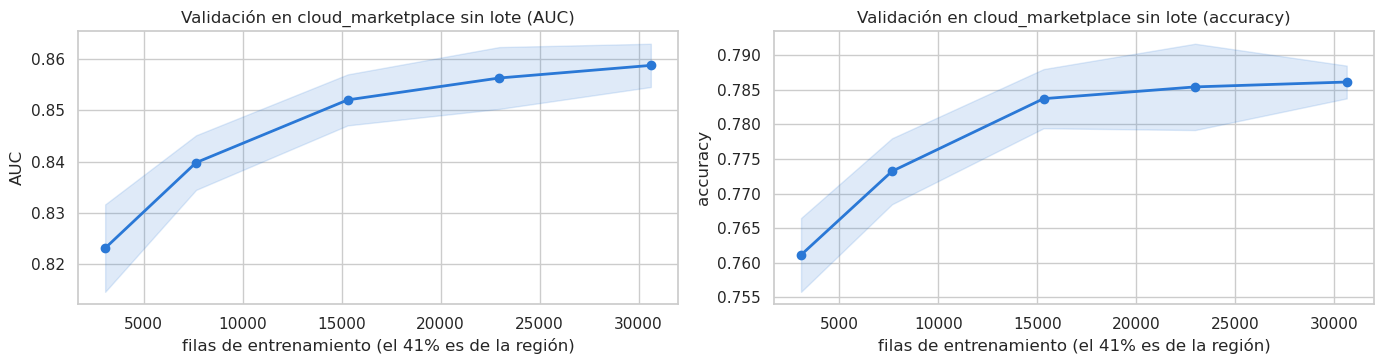

,filas_entrenamiento,auc,accuracy
fracción del fold,,,
10%,3062,0.8232,0.7611
25%,7654,0.8398,0.7732
50%,15309,0.8520,0.7837
75%,22964,0.8563,0.7854
100%,30618,0.8588,0.7861


Umbral que maximiza la accuracy en la región: 0.48 (accuracy 0.7876, contra 0.7860 con 0,5).


In [33]:
@memory.cache
def learning_curve_proba(model, X, y, scheme, fractions):
    # Igual que learning_curve_scores, pero devuelve la probabilidad predicha para cada fila de
    # validación, para poder medir cualquier subgrupo.
    cv, groups = CV_SCHEMES[scheme]
    parts = []
    for fold, (train, validation) in enumerate(cv.split(X, y, groups)):
        order = np.random.RandomState(RANDOM_STATE).permutation(train)
        for fraction in fractions:
            subset = order[:int(round(fraction * len(train)))]
            fitted = clone(model).fit(X.iloc[subset], y.iloc[subset])
            parts.append(pd.DataFrame({
                'fold': fold, 'fraccion': fraction, 'filas_entrenamiento': len(subset),
                'proba': fitted.predict_proba(X.iloc[validation])[:, 1],
            }, index=X.index[validation]))
    return pd.concat(parts)


curve = learning_curve_proba(baseline, X_dev_prep, y_dev, 'aleatoria', TRAIN_FRACTIONS)
curve = curve.loc[region_mask.loc[curve.index].to_numpy()].copy()
curve[TARGET] = y_dev.loc[curve.index].to_numpy()
region_curve = curve.groupby(['fraccion', 'fold'])[['filas_entrenamiento', TARGET, 'proba']].apply(
    lambda g: pd.Series({
        'filas_entrenamiento': g['filas_entrenamiento'].iloc[0],
        'auc': roc_auc_score(g[TARGET], g['proba']),
        'accuracy': ((g['proba'] >= THRESHOLD).astype(int) == g[TARGET]).mean(),
    }))
region_curve_mean = region_curve.groupby('fraccion').mean()
region_curve_std = region_curve.groupby('fraccion').std()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, metric in zip(axes, ['auc', 'accuracy']):
    values = region_curve_mean[metric]
    ax.plot(region_curve_mean['filas_entrenamiento'], values, marker='o', linewidth=2, markersize=6, color=BLUE)
    ax.fill_between(region_curve_mean['filas_entrenamiento'], values - region_curve_std[metric],
                    values + region_curve_std[metric], color=BLUE, alpha=0.15)
    ax.set_xlabel(f'filas de entrenamiento (el {region_mask.mean():.0%} es de la región)')
    ax.set_ylabel(metric.upper() if metric == 'auc' else 'accuracy')
    ax.set_title(f'Validación en cloud_marketplace sin lote ({"AUC" if metric == "auc" else "accuracy"})')
plt.tight_layout()
plt.show()

region_summary = region_curve_mean[['filas_entrenamiento', 'auc', 'accuracy']].copy()
region_summary.index = [f'{fraction:.0%}' for fraction in region_summary.index]
region_summary.index.name = 'fracción del fold'
display(region_summary.style.format({'filas_entrenamiento': '{:.0f}', 'auc': '{:.4f}', 'accuracy': '{:.4f}'}))

region_rows = analysis.loc[region_mask]
thresholds = np.round(np.arange(0.30, 0.701, 0.01), 2)
region_accuracy = pd.Series(
    [((region_rows['proba'] >= t).astype(int) == region_rows[TARGET]).mean() for t in thresholds], index=thresholds)
print(f'Umbral que maximiza la accuracy en la región: {region_accuracy.idxmax():.2f} '
      f'(accuracy {region_accuracy.max():.4f}, contra {region_accuracy.loc[0.5]:.4f} con 0,5).')

**Lo que no explica el error:**

- **La falta de filas:**
  - En la región, la AUC sube de 0,852 a 0,859 entre la mitad de los datos y el total, y la accuracy apenas de 0,784 a 0,786.
  - Más reservas del mismo tipo ayudarían algo a ordenar por riesgo, pero casi nada a la decisión 0/1.
- **El umbral:** el que maximiza la accuracy en la región es 0,48 y la mejora en 0,2 puntos. Con probabilidades calibradas, 0,5 ya es casi óptimo en cada cohorte.
- **Etiquetas ruidosas:** no se puede medir, porque en las reservas únicas no hay gemelas para detectar etiquetas contradictorias. **Inferencia:** la etiqueta se deriva del estado de ejecución que registra el sistema (`execution_status`), así que no hay motivos para esperar mucho ruido.

**Causas probables** (**inferencia**, con la evidencia de 7.2 y 7.3):

1. **No hay información sobre quién reserva.** Sólo el 0,9 % de las reservas de la región tiene cancelaciones previas, contra el 10,9 % del resto. Casi ninguna tiene organización ni es de un cliente que vuelve. Una reserva individual hecha a través de un broker llega sin historial.
2. **Faltan las señales fuertes.** Ninguna tiene `locked_allocation` ni es parte de un lote, que son las dos señales con las que el modelo acierta casi siempre.
3. **El modelo usa una señal débil como sustituto.** Se apoya en `special_resource_requests`:
   - sin pedidos especiales, predice cancelaciones de más (35 % de falsos positivos);
   - con pedidos, deja pasar la mayoría de las cancelaciones.
4. **Queda por descartar que otro modelo extraiga más de las mismas variables.** Se prueba en el paso 4.

### 9.3 Próximos pasos

Opciones para mejorar la región:

1. **Agregar información derivada** (paso 4, feature engineering). Son variables que se pueden calcular con las columnas actuales y que podrían distinguir mejor a las reservas individuales:
   - el día de la semana de la ejecución y si cae en fin de semana;
   - totales y proporciones: horas GPU totales, proporción de horas pico y procesos totales;
   - el costo total estimado (costo por hora por horas GPU) y el costo por proceso.

   Cada una se evalúa con diferencias pareadas contra el baseline, también dentro de la región.
2. **Incorporar datos nuevos** (sección 10): historial del cliente, actividad previa a la ejecución y condiciones comerciales.
3. **Usar una métrica específica para la región en la selección de modelos.** En el paso 4, cada estrategia se reporta con la AUC y el error de la región, además de los globales.
4. **Probar otro modelo** (gradient boosting) para ver si extrae más de las mismas variables en la región.

**Descartadas:**

- **Más filas del mismo tipo:** la curva de la región casi no mejora la accuracy.
- **Un umbral distinto para la región:** gana 0,2 puntos.
- **Data augmentation o SMOTE:** en datos tabulares pueden generar combinaciones imposibles de variables. Además, el problema de la región no es el desbalance (36 % de cancelaciones), sino que con estas variables las clases no se separan.
- **Un modelo separado para la región:** no agrega información, y un Random Forest ya puede separar por `client_type` en sus primeros cortes. **Inferencia.**

**Siguientes cohortes candidatas:**
- los clientes que casi no cancelan: en `independent_client`, `sponsored_project` y `high_priority_partner` pasa sin aviso entre el 67 % y el 92 % de las cancelaciones;
- los lotes nunca vistos, que dependen sobre todo de registrar un identificador de lote (sección 10).

## 10. Adquisición de datos (consigna 3.4)

El diagnóstico dice que lo que falta es información, no filas. Por eso las propuestas son variables nuevas que la plataforma podría registrar, no más reservas del mismo tipo. Antes se mide cuánto mejora el modelo cuando ya tiene algo de historial del cliente, comparando sólo reservas únicas.

In [34]:
has_history = (analysis['previous_job_cancellations'].gt(0) | analysis['successful_previous_jobs'].gt(0)
               | analysis['returning_client'].eq(1) | analysis['organization_id'].notna())
single = analysis['en_lote'].eq('única')
history_label = has_history.map({True: 'con algún historial', False: 'sin historial'})
print('Reservas únicas, según si traen algún dato del cliente '
      '(cancelaciones o trabajos previos, cliente que vuelve u organización):')
show_errors(error_table(history_label[single], frame=analysis.loc[single]))

Reservas únicas, según si traen algún dato del cliente (cancelaciones o trabajos previos, cliente que vuelve u organización):


,filas,porcentaje_filas,tasa_cancelacion,error,porcentaje_errores,tasa_fp,tasa_fn,auc,error_agrupada
sin historial,21654,92.5%,29.4%,18.6%,97.0%,9.8%,39.7%,0.876,18.7%
con algún historial,1748,7.5%,20.2%,7.2%,3.0%,0.6%,32.9%,0.916,7.2%


Cuando una reserva única trae algún dato del cliente, el modelo la ordena mejor: la AUC es 0,916 con historial y 0,876 sin él.

- Se compara la AUC y no el error, porque las reservas con historial se cancelan menos (20 % contra 29 %) y el error depende de esa tasa.
- Es una asociación, no una prueba: los clientes con historial pueden ser distintos por otros motivos. Aun así, sugiere que el historial aporta información que hoy falta en la región elegida.

**Datos que se incorporarían, por prioridad** (**inferencia**: son datos que la plataforma podría registrar):

| Prioridad | Dato | Qué se registraría | Qué error ataca | Evidencia en los datos actuales |
|---|---|---|---|---|
| 1 | Historial del cliente final | Un identificador estable del cliente, aunque reserve por un broker, con sus cancelaciones y ejecuciones previas en toda la plataforma y su antigüedad | La región elegida (77 % de los errores) y los clientes directos que casi no cancelan | Sólo el 0,9 % de la región tiene cancelaciones previas. En las reservas únicas, con historial la AUC sube de 0,876 a 0,916. Con una cancelación previa, la tasa es del 96 %. |
| 2 | Identificador de lote | Un ID común para las reservas creadas juntas, con el tamaño del lote | Los lotes nunca vistos: su error sube de 0,5 %–5 % a 4 %–17 % con validación agrupada | La tasa pasa de 28 % en reservas únicas a 95 % en lotes de más de 50. Hoy el lote sólo se infiere por filas idénticas, y un lote con pequeñas diferencias entre reservas no se detecta. |
| 3 | Actividad entre la reserva y la ejecución | Eventos con fecha: confirmación, carga de datos o imágenes de contenedor, consultas a la API y cambios en la reserva | Los falsos negativos que se parecen a reservas que se ejecutan | `resource_modifications` es el único dato de actividad posterior a la reserva y aporta de forma consistente (6.4). Con modificaciones se cancela el 17,5 %; sin ellas, el 45,3 %. |
| 4 | Condiciones comerciales | Penalidad por cancelación, reembolso, y precio pagado frente a precio vigente | La región elegida, que es 99,96 % `no_commitment` | El compromiso es la señal más fuerte del dataset (`locked_allocation` se cancela el 99,7 %), pero dentro de `no_commitment` no hay más detalle. |

- **Por qué este orden:**
  - El historial ataca la mayor fuente de error.
  - El identificador de lote es barato de registrar, porque la plataforma ya sabe qué reservas se crearon juntas.
  - La actividad obliga a definir en qué momento se predice.
  - Las condiciones comerciales dependen de la política de la empresa.
- **Leakage:** la actividad tiene que registrarse con fecha, y sólo se puede usar la anterior al momento de la predicción, por ejemplo 48 horas antes de la ejecución. Es el mismo criterio que llevó a excluir `assigned_gpu_type` y `queue_wait_time`.
- **Privacidad:** el identificador del cliente puede estar seudonimizado; alcanza con que sea estable.
- **Cómo se mediría:**
  - con la misma validación cruzada, aleatoria y agrupada;
  - con la diferencia pareada contra el modelo sin el dato nuevo;
  - globalmente y dentro de la región.
- **Lo que no se propone:** conseguir más reservas del mismo tipo. Las curvas de aprendizaje (secciones 8 y 9.2) muestran que agregarían poco.

## 11. Optimización del sistema (consigna 4)

Se exploran tres estrategias, en el orden que sugiere el diagnóstico:

1. **Feature engineering y selección de variables**, con el baseline fijo. Es el enfoque centrado en los datos de la sección 9.
2. **Selección de modelos:** gradient boosting contra Random Forest.
3. **Búsqueda de hiperparámetros** de los dos modelos. Si quedan cerca, se prueba además combinarlos.

**Regla para adoptar un cambio**, fijada antes de ver los resultados:

- con las diferencias pareadas fold a fold, la AUC media de la validación aleatoria tiene que mejorar, y en al menos 4 de los 5 folds;
- la AUC media de la validación agrupada no tiene que empeorar.

Cada variante se reporta además con la AUC y el error de la región elegida en 9 (reservas individuales de `cloud_marketplace`), como métrica específica de la cohorte prioritaria.

In [35]:
from scipy.stats import loguniform
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder

Y_DEV = y_dev.to_numpy()
REGION = region_mask.to_numpy()

# Fold de validación de cada fila en cada esquema: son los mismos folds de toda la validación.
FOLD_IDS = {}
for scheme, (cv, groups) in CV_SCHEMES.items():
    fold_id = np.empty(len(y_dev), dtype=int)
    for fold, (_, validation) in enumerate(cv.split(X_dev_prep, y_dev, groups)):
        fold_id[validation] = fold
    FOLD_IDS[scheme] = fold_id


def scores_from_proba(proba):
    # Métricas por fold a partir de predicciones out-of-fold, para los dos esquemas.
    result = {}
    for scheme, fold_id in FOLD_IDS.items():
        scheme_proba = proba[scheme]
        result[scheme] = {
            'proba': scheme_proba,
            'auc': np.array([roc_auc_score(Y_DEV[fold_id == k], scheme_proba[fold_id == k])
                             for k in range(N_FOLDS)]),
            'accuracy': np.array([((scheme_proba[fold_id == k] >= THRESHOLD) == Y_DEV[fold_id == k]).mean()
                                  for k in range(N_FOLDS)]),
        }
    return result


def evaluate(model, X):
    return scores_from_proba({scheme: out_of_fold_proba(model, X, y_dev, scheme) for scheme in CV_SCHEMES})


def compare(candidates, reference):
    rows = []
    for name, result in candidates.items():
        row = {'variante': name}
        for scheme, suffix in [('aleatoria', ''), ('agrupada', '_agrupada')]:
            delta_auc = result[scheme]['auc'] - reference[scheme]['auc']
            delta_accuracy = result[scheme]['accuracy'] - reference[scheme]['accuracy']
            row[f'auc{suffix}'] = result[scheme]['auc'].mean()
            row[f'delta_auc{suffix}'] = delta_auc.mean()
            if scheme == 'aleatoria':
                row['folds_que_mejoran'] = int((delta_auc > 0).sum())
                row['accuracy'] = result[scheme]['accuracy'].mean()
                row['delta_accuracy'] = delta_accuracy.mean()
        proba = result['aleatoria']['proba']
        row['auc_region'] = roc_auc_score(Y_DEV[REGION], proba[REGION])
        row['error_region'] = ((proba[REGION] >= THRESHOLD) != Y_DEV[REGION]).mean()
        row['cumple_regla'] = (row['delta_auc'] > 0 and row['folds_que_mejoran'] >= 4
                               and row['delta_auc_agrupada'] >= 0)
        rows.append(row)
    return pd.DataFrame(rows).set_index('variante')


COMPARE_FORMAT = {
    'auc': '{:.4f}', 'delta_auc': '{:+.4f}', 'accuracy': '{:.4f}', 'delta_accuracy': '{:+.4f}',
    'auc_agrupada': '{:.4f}', 'delta_auc_agrupada': '{:+.4f}', 'auc_region': '{:.4f}', 'error_region': '{:.1%}',
}

baseline_eval = evaluate(baseline, X_dev_prep)
print(f"Baseline: AUC {baseline_eval['aleatoria']['auc'].mean():.4f} (aleatoria), "
      f"{baseline_eval['agrupada']['auc'].mean():.4f} (agrupada). "
      f"Región: AUC {roc_auc_score(Y_DEV[REGION], baseline_eval['aleatoria']['proba'][REGION]):.4f}.")

Baseline: AUC 0.9557 (aleatoria), 0.9374 (agrupada). Región: AUC 0.8598.


### 11.1 Feature engineering y selección de variables

Con Random Forest fijo, se agregan grupos de variables derivadas de las columnas actuales (las candidatas de 9.3). Todas son transformaciones fijas, que no aprenden de los datos:

- **calendario:** día de la semana de la ejecución y si cae en fin de semana;
- **totales:** horas GPU totales, proporción de horas pico y procesos totales;
- **costo:** costo total estimado (costo por hora por horas GPU) y costo por proceso;
- **reserva:** día de la semana en que se hizo la reserva (fecha de ejecución menos `hours_before_execution`).

Para la selección de variables se prueba quitar `execution_year`, que quedó pendiente en el EDA (sección 3.6).

In [36]:
def add_derived_features(prepared):
    derived = prepared.copy()
    execution_date = pd.to_datetime(dict(year=derived['execution_year'], month=derived['execution_month'],
                                         day=derived['execution_day']), errors='coerce')
    derived['execution_weekday'] = execution_date.dt.weekday.astype(float)
    derived['execution_weekend'] = execution_date.dt.weekday.ge(5).astype(float).where(execution_date.notna())
    gpu_hours = derived['peak_gpu_hours'] + derived['offpeak_gpu_hours']
    derived['total_gpu_hours'] = gpu_hours
    derived['peak_share'] = (derived['peak_gpu_hours'] / gpu_hours).where(gpu_hours > 0, 0.0)
    processes = (derived['num_primary_processes'] + derived['num_auxiliary_processes'].fillna(0)
                 + derived['num_background_processes'])
    derived['total_processes'] = processes
    derived['total_cost'] = derived['estimated_cost_per_hour'] * gpu_hours
    derived['cost_per_process'] = (derived['estimated_cost_per_hour'] / processes).where(processes > 0, 0.0)
    booking_date = execution_date - pd.to_timedelta(derived['hours_before_execution'], unit='h')
    derived['booking_weekday'] = booking_date.dt.weekday.astype(float)
    return derived


DERIVED_GROUPS = {
    'calendario': ['execution_weekday', 'execution_weekend'],
    'totales': ['total_gpu_hours', 'peak_share', 'total_processes'],
    'costo': ['total_cost', 'cost_per_process'],
    'reserva': ['booking_weekday'],
}
all_derived = [c for columns in DERIVED_GROUPS.values() for c in columns]
X_dev_derived = add_derived_features(X_dev_prep)

feature_candidates = {
    f'+ {name}': evaluate(forest_pipeline(numeric=NUMERIC_FEATURES + columns, **BEST_FOREST), X_dev_derived)
    for name, columns in DERIVED_GROUPS.items()
}
feature_candidates['+ todas las derivadas'] = evaluate(
    forest_pipeline(numeric=NUMERIC_FEATURES + all_derived, **BEST_FOREST), X_dev_derived)
feature_candidates['- execution_year'] = evaluate(
    forest_pipeline(numeric=[c for c in NUMERIC_FEATURES if c != 'execution_year'], **BEST_FOREST), X_dev_prep)

feature_results = compare(feature_candidates, baseline_eval)
display(feature_results.style.format(COMPARE_FORMAT))

,auc,delta_auc,folds_que_mejoran,accuracy,delta_accuracy,auc_agrupada,delta_auc_agrupada,auc_region,error_region,cumple_regla
variante,,,,,,,,,,
+ calendario,0.9555,-0.0002,1,0.8843,-0.0001,0.9373,-0.0002,0.8592,21.4%,False
+ totales,0.9547,-0.0010,0,0.8836,-0.0008,0.9363,-0.0011,0.8570,21.5%,False
+ costo,0.9550,-0.0007,1,0.8846,+0.0001,0.9357,-0.0017,0.8565,21.3%,False
+ reserva,0.9559,+0.0001,3,0.8862,+0.0017,0.9371,-0.0003,0.8608,21.0%,False
+ todas las derivadas,0.9543,-0.0014,0,0.8824,-0.0020,0.9339,-0.0036,0.8549,21.7%,False
- execution_year,0.9543,-0.0014,0,0.8833,-0.0012,0.9360,-0.0014,0.8542,21.7%,False


- **Ninguna variable derivada cumple la regla.**
  - Las de calendario, totales y costo empeoran la AUC en casi todos los folds.
  - Agregarlas todas juntas es lo peor: −0,0014 con validación aleatoria y −0,0036 con la agrupada.
- **El día de la semana de la reserva es el caso más cercano.** Sube la accuracy 0,0017 y baja el error de la región de 21,4 % a 21,0 %. Pero la AUC mejora sólo en 3 de 5 folds y empeora con la validación agrupada, así que no se adopta.
- **Por qué no ayudan (inferencia):**
  - Son funciones de columnas que el modelo ya tiene, y un bosque de árboles profundos puede aproximarlas con varios cortes.
  - A cambio, cada variable nueva diluye a las que importan en el sorteo de variables de cada división.
  - Coincide con el diagnóstico: falta información, no otras formas de la misma información.
- **`execution_year` se conserva:** quitarla empeora en los 5 folds (−0,0014). La limitación para reservas de años futuros (sección 3.6) queda como riesgo documentado.

### 11.2 Selección de modelos: gradient boosting

Se compara Random Forest con `HistGradientBoostingClassifier`, la implementación de gradient boosting de scikit-learn inspirada en LightGBM. Random Forest promedia árboles profundos e independientes para reducir varianza. Boosting entrena árboles en secuencia, cada uno sobre los errores de los anteriores, para reducir sesgo.

Preprocesamiento propio de este modelo:

- las numéricas pasan sin imputar, porque el modelo maneja los faltantes;
- las categóricas usan la codificación nativa del modelo, con las de menos de 50 filas agrupadas y las no vistas tratadas como faltante.

SVM y kNN no se prueban, por los motivos de la sección 6.

In [37]:
def boosting_pipeline(numeric=NUMERIC_FEATURES, categorical=CATEGORICAL_FEATURES, **params):
    preprocess = ColumnTransformer([
        ('numericas', 'passthrough', list(numeric)),
        ('categoricas', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan,
                                       encoded_missing_value=np.nan, min_frequency=MIN_CATEGORY_ROWS),
         list(categorical)),
    ])
    is_categorical = [False] * len(numeric) + [True] * len(categorical)
    model = HistGradientBoostingClassifier(categorical_features=is_categorical, random_state=RANDOM_STATE, **params)
    return Pipeline([('preprocesamiento', preprocess), ('modelo', model)])


model_candidates = {
    'gradient boosting (valores por defecto)': evaluate(boosting_pipeline(), X_dev_prep),
    'gradient boosting (por defecto) + derivadas': evaluate(
        boosting_pipeline(numeric=NUMERIC_FEATURES + all_derived), X_dev_derived),
}
display(compare(model_candidates, baseline_eval).style.format(COMPARE_FORMAT))

,auc,delta_auc,folds_que_mejoran,accuracy,delta_accuracy,auc_agrupada,delta_auc_agrupada,auc_region,error_region,cumple_regla
variante,,,,,,,,,,
gradient boosting (valores por defecto),0.9463,-0.0094,0,0.8685,-0.0159,0.9372,-0.0002,0.8594,21.7%,False
gradient boosting (por defecto) + derivadas,0.9469,-0.0088,0,0.8691,-0.0153,0.9365,-0.0009,0.8595,21.7%,False


- **Con los valores por defecto, gradient boosting rinde menos con validación aleatoria:** queda 0,009 de AUC y 1,6 puntos de accuracy debajo de Random Forest. Con la agrupada empata (0,9372 contra 0,9374).
- **Inferencia:** la diferencia está en la memorización de lotes.
  - Por defecto, los árboles de boosting tienen como máximo 31 hojas y no alcanzan a "recordar" cada reserva en lote. El Random Forest sin límite de profundidad sí.
  - Con reservas nunca vistas, donde memorizar no sirve, los dos rinden igual.
- **Las variables derivadas tampoco ayudan a gradient boosting.**

### 11.3 Búsqueda de hiperparámetros

- **Gradient boosting:** búsqueda aleatoria de 30 combinaciones con validación aleatoria, eligiendo por AUC.
  - Hiperparámetros: tasa de aprendizaje, número máximo de hojas por árbol, mínimo de filas por hoja, regularización L2 y fracción de variables por división.
  - El número de árboles se fija con *early stopping* sobre un 10 % interno del fold de entrenamiento.
  - Con varios hiperparámetros, una búsqueda aleatoria cubre mejor los rangos que una grilla del mismo costo, porque no repite valores de los hiperparámetros que importan.
- **Random Forest:** grilla de `max_features`, la fracción de variables que cada división considera. La profundidad y las hojas ya se ajustaron en 6.2.

In [38]:
BOOSTING_SPACE = {
    'modelo__learning_rate': loguniform(0.03, 0.3),
    'modelo__max_leaf_nodes': [31, 63, 127, 255, 511],
    'modelo__min_samples_leaf': [1, 2, 5, 10, 20, 50],
    'modelo__l2_regularization': [0.0, 0.01, 0.1, 1.0, 10.0],
    'modelo__max_features': [0.5, 0.7, 1.0],
}
SEARCH_ITERATIONS = 30


@memory.cache
def boosting_search(X, y, n_iter):
    model = boosting_pipeline(max_iter=2000, early_stopping=True, n_iter_no_change=30)
    search = RandomizedSearchCV(model, BOOSTING_SPACE, n_iter=n_iter, scoring=SCORING, refit=False,
                                cv=CV_SCHEMES['aleatoria'][0], random_state=RANDOM_STATE)
    search.fit(X, y)
    return pd.DataFrame(search.cv_results_)


search_results = boosting_search(X_dev_prep, y_dev, SEARCH_ITERATIONS)
search_table = (search_results
                .rename(columns=lambda c: c.replace('param_modelo__', ''))
                [['learning_rate', 'max_leaf_nodes', 'min_samples_leaf', 'l2_regularization', 'max_features',
                  'mean_test_auc', 'std_test_auc', 'mean_test_accuracy', 'mean_fit_time']]
                .sort_values('mean_test_auc', ascending=False))
display(search_table.head(8).style.format({
    'learning_rate': '{:.3f}', 'mean_test_auc': '{:.4f}', 'std_test_auc': '{:.4f}',
    'mean_test_accuracy': '{:.4f}', 'mean_fit_time': '{:.1f}'}))

best_boosting_params = {name.replace('modelo__', ''): value
                        for name, value in search_results.loc[search_results['mean_test_auc'].idxmax(), 'params'].items()}
print('Mejor combinación:', best_boosting_params)

,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features,mean_test_auc,std_test_auc,mean_test_accuracy,mean_fit_time
27,0.048,127,5,0.100000,0.500000,0.9546,0.0021,0.8817,14.3
25,0.032,127,1,0.010000,0.500000,0.9545,0.0018,0.8818,19.4
4,0.060,511,10,0.000000,0.700000,0.9542,0.0013,0.8820,16.5
15,0.073,511,2,10.000000,0.700000,0.9538,0.0019,0.8808,25.0
2,0.042,511,2,1.000000,1.000000,0.9537,0.0018,0.8821,20.7
18,0.059,127,5,1.000000,1.000000,0.9536,0.0022,0.8814,9.9
6,0.070,127,10,1.000000,0.700000,0.9536,0.0017,0.8812,9.3
1,0.043,127,20,0.010000,1.000000,0.9533,0.0019,0.8802,10.2


Mejor combinación: {'l2_regularization': 0.1, 'learning_rate': np.float64(0.04788312427249216), 'max_features': 0.5, 'max_leaf_nodes': 127, 'min_samples_leaf': 5}


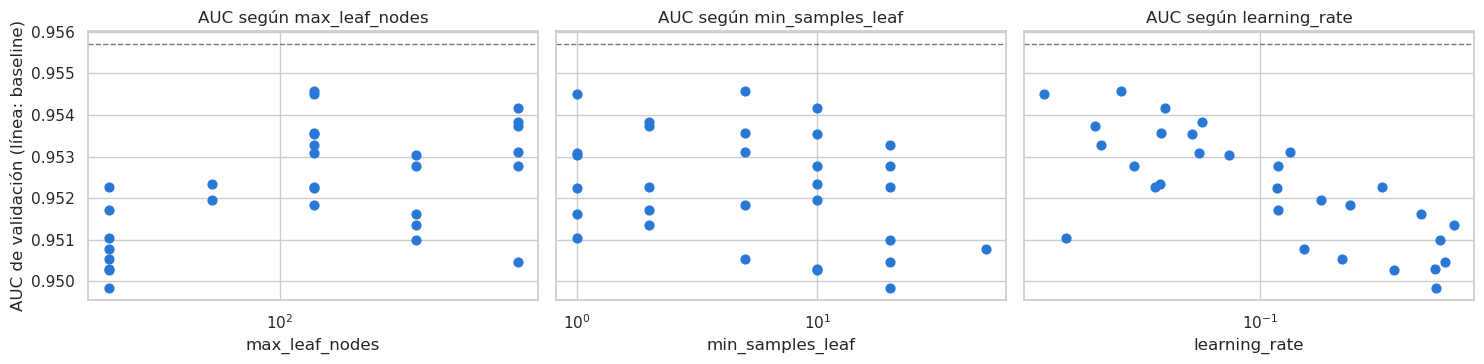

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, column in zip(axes, ['max_leaf_nodes', 'min_samples_leaf', 'learning_rate']):
    ax.scatter(search_table[column].astype(float), search_table['mean_test_auc'], color=BLUE, s=40)
    ax.axhline(baseline_eval['aleatoria']['auc'].mean(), color=REFERENCE, linestyle='--', linewidth=1)
    ax.set_xscale('log')
    ax.set_xlabel(column)
    ax.set_title(f'AUC según {column}')
axes[0].set_ylabel('AUC de validación (línea: baseline)')
plt.tight_layout()
plt.show()

- **La mejor combinación queda debajo del baseline.** Usa una tasa de aprendizaje baja (0,048), árboles de hasta 127 hojas, hojas de al menos 5 filas, poca regularización y la mitad de las variables en cada división. Llega a 0,9546 de AUC, contra 0,9557 del baseline.
- **Patrón de los gráficos:** los árboles de 31 hojas y las tasas de aprendizaje altas rinden peor. Árboles más grandes acercan gradient boosting a Random Forest, porque le permiten memorizar más.
- **Meseta, no óptimo:** las mejores combinaciones van de 0,953 a 0,955, una diferencia del orden del desvío entre folds (alrededor de 0,002). La búsqueda no encontró un óptimo marcado.

In [40]:
MAX_FEATURES_GRID = ['sqrt', 0.2, 0.35, 0.5]
forest_feature_rows = []
for max_features in MAX_FEATURES_GRID:
    scores = cross_validate_scores(forest_pipeline(max_features=max_features, **BEST_FOREST),
                                   X_dev_prep, y_dev, 'aleatoria')
    forest_feature_rows.append({'max_features': str(max_features), **summarize(scores)})
forest_feature_results = pd.DataFrame(forest_feature_rows).set_index('max_features')
display(forest_feature_results.round(4))
best_max_features = MAX_FEATURES_GRID[int(np.argmax(forest_feature_results['auc_val'].to_numpy()))]
print('Mejor max_features:', best_max_features)

,auc_val,auc_val_std,auc_train,accuracy_val,accuracy_train
max_features,,,,,
sqrt,0.9557,0.0017,0.9997,0.8847,0.9967
0.2,0.9564,0.0019,0.9997,0.8858,0.9967
0.35,0.9558,0.0017,0.9997,0.8855,0.9967
0.5,0.9550,0.0018,0.9997,0.8836,0.9967


Mejor max_features: 0.2


- **`max_features = 0,2` es el mejor valor.** Cada división considera 27 de las 139 columnas codificadas, en lugar de 11 con `sqrt`. La AUC sube a 0,9564 y la accuracy a 0,886.
- **Con más variables por división (0,5) empeora.** `max_features` controla la diversidad del bosque: si cada división ve muchas variables, los árboles se parecen más entre sí y el promedio atenúa menos sus errores.

In [41]:
tuned_boosting = boosting_pipeline(max_iter=2000, early_stopping=True, n_iter_no_change=30, **best_boosting_params)
tuned_forest = forest_pipeline(max_features=best_max_features, **BEST_FOREST)
tuned_candidates = {
    'gradient boosting ajustado': evaluate(tuned_boosting, X_dev_prep),
    f'Random Forest, max_features = {best_max_features}': evaluate(tuned_forest, X_dev_prep),
}
display(compare(tuned_candidates, baseline_eval).style.format(COMPARE_FORMAT))

,auc,delta_auc,folds_que_mejoran,accuracy,delta_accuracy,auc_agrupada,delta_auc_agrupada,auc_region,error_region,cumple_regla
variante,,,,,,,,,,
gradient boosting ajustado,0.9546,-0.0011,0,0.8817,-0.0027,0.9401,+0.0026,0.8653,21.2%,False
"Random Forest, max_features = 0.2",0.9564,+0.0007,5,0.8860,+0.0016,0.9392,+0.0017,0.8617,21.0%,True


- **Random Forest con `max_features = 0,2` cumple la regla y se adopta.** Mejora +0,0007 de AUC en los 5 folds, +0,0016 de accuracy y +0,0017 con validación agrupada.
- **Gradient boosting ajustado no cumple la regla:** pierde 0,0011 de AUC con validación aleatoria.
  - Pero es el mejor modelo con reservas nunca vistas (0,9401 de AUC agrupada, +0,0026) y en la región elegida (AUC 0,865).
  - Es fuerte justo donde Random Forest es más débil, y eso lo hace candidato para combinarlos.

### 11.4 Combinación de modelos

Promediar las probabilidades de dos modelos sólo ayuda si se equivocan en filas distintas: si sus predicciones están muy correlacionadas, la combinación aporta poco. Como todos los modelos usan los mismos folds, el promedio de sus predicciones *out-of-fold* es exactamente la predicción *out-of-fold* del ensamble, sin reentrenar.

In [42]:
forest_for_ensemble = tuned_candidates[f'Random Forest, max_features = {best_max_features}']
boosting_for_ensemble = tuned_candidates['gradient boosting ajustado']
correlation = np.corrcoef(forest_for_ensemble['aleatoria']['proba'], boosting_for_ensemble['aleatoria']['proba'])[0, 1]
disagreement = ((forest_for_ensemble['aleatoria']['proba'] >= THRESHOLD)
                != (boosting_for_ensemble['aleatoria']['proba'] >= THRESHOLD)).mean()
print(f'Correlación entre las probabilidades out-of-fold: {correlation:.3f}. '
      f'Filas en que las decisiones difieren: {disagreement:.1%}.')

ensemble_candidates = {}
for weight in [0.25, 0.5, 0.75]:
    averaged = {scheme: weight * forest_for_ensemble[scheme]['proba']
                + (1 - weight) * boosting_for_ensemble[scheme]['proba'] for scheme in CV_SCHEMES}
    ensemble_candidates[f'promedio ({weight:.0%} Random Forest)'] = scores_from_proba(averaged)
print('Frente al baseline:')
display(compare(ensemble_candidates, baseline_eval).style.format(COMPARE_FORMAT))
print(f'Frente a Random Forest ajustado (max_features = {best_max_features}), el modelo al que se suma:')
display(compare(ensemble_candidates, forest_for_ensemble).style.format(COMPARE_FORMAT))

Correlación entre las probabilidades out-of-fold: 0.976. Filas en que las decisiones difieren: 4.2%.


Frente al baseline:


,auc,delta_auc,folds_que_mejoran,accuracy,delta_accuracy,auc_agrupada,delta_auc_agrupada,auc_region,error_region,cumple_regla
variante,,,,,,,,,,
promedio (25% Random Forest),0.9567,+0.0010,5,0.8839,-0.0005,0.9415,+0.0041,0.8676,21.1%,True
promedio (50% Random Forest),0.9576,+0.0019,5,0.8857,+0.0013,0.9418,+0.0044,0.8680,21.1%,True
promedio (75% Random Forest),0.9576,+0.0019,5,0.8867,+0.0023,0.9411,+0.0037,0.8661,21.0%,True


Frente a Random Forest ajustado (max_features = 0.2), el modelo al que se suma:


,auc,delta_auc,folds_que_mejoran,accuracy,delta_accuracy,auc_agrupada,delta_auc_agrupada,auc_region,error_region,cumple_regla
variante,,,,,,,,,,
promedio (25% Random Forest),0.9567,+0.0003,3,0.8839,-0.0021,0.9415,+0.0023,0.8676,21.1%,False
promedio (50% Random Forest),0.9576,+0.0012,5,0.8857,-0.0003,0.9418,+0.0026,0.8680,21.1%,True
promedio (75% Random Forest),0.9576,+0.0012,5,0.8867,+0.0007,0.9411,+0.0019,0.8661,21.0%,True


- **Las predicciones de los dos modelos están muy correlacionadas** (0,976), y sus decisiones difieren en el 4,2 % de las filas. Aun así el promedio mejora, porque sus errores no son idénticos.
- **Frente a Random Forest ajustado, el promedio 50/50 y el 75/25 cumplen la regla:** +0,0012 de AUC en los 5 folds y entre +0,0019 y +0,0026 con validación agrupada. Con 25 % de Random Forest no la cumple.
- **Comparación entre los dos:** el 50/50 es mejor con reservas nuevas (0,9418) y en la región (AUC 0,868); el 75/25, en accuracy (0,8867 contra 0,8857). Ambas diferencias están dentro del ruido entre folds.
- **Se elige el promedio simple (50/50).** Es la combinación estándar, y no requiere elegir pesos con los mismos datos que se usan para evaluarla.
- **Stacking no se prueba.** Consiste en entrenar un meta-modelo sobre las predicciones *out-of-fold*. Con predicciones tan correlacionadas, un meta-modelo tiene poco que aprender más allá de un promedio, y para ajustarlo haría falta otra capa de validación.

### 11.5 Tamaño del modelo y número de árboles

El predictor se envía por mail, así que el tamaño del archivo importa. Un Random Forest con árboles sin límite de profundidad guarda decenas de miles de nodos por árbol.

Para medir cuánto se pierde con menos árboles no hace falta reentrenar: con la misma semilla, los primeros *k* árboles de un bosque de 300 son exactamente un bosque de *k* árboles. Se guardan las predicciones acumuladas de cada fold.

In [43]:
import tempfile

import joblib

TREE_COUNTS = (50, 100, 150, 200, 300)


@memory.cache
def forest_oof_by_trees(model, X, y, scheme, tree_counts):
    # Predicciones out-of-fold de un Random Forest usando sólo sus primeros k árboles.
    cv, groups = CV_SCHEMES[scheme]
    result = {k: np.zeros(len(y)) for k in tree_counts}
    for train, validation in cv.split(X, y, groups):
        fitted = clone(model).fit(X.iloc[train], y.iloc[train])
        encoded = fitted[:-1].transform(X.iloc[validation])
        cumulative = np.cumsum([tree.predict_proba(encoded)[:, 1] for tree in fitted[-1].estimators_], axis=0)
        for k in tree_counts:
            result[k][validation] = cumulative[k - 1] / k
    return result


forest_by_trees = {scheme: forest_oof_by_trees(tuned_forest, X_dev_prep, y_dev, scheme, TREE_COUNTS)
                   for scheme in CV_SCHEMES}
assert np.allclose(forest_by_trees['aleatoria'][300], forest_for_ensemble['aleatoria']['proba'])

tree_candidates = {}
for k in TREE_COUNTS:
    tree_candidates[f'Random Forest, {k} árboles'] = scores_from_proba(
        {scheme: forest_by_trees[scheme][k] for scheme in CV_SCHEMES})
for k in [100, 300]:
    tree_candidates[f'promedio 50 % (Random Forest de {k} árboles)'] = scores_from_proba(
        {scheme: 0.5 * forest_by_trees[scheme][k] + 0.5 * boosting_for_ensemble[scheme]['proba']
         for scheme in CV_SCHEMES})
print(f'Frente a Random Forest ajustado de 300 árboles:')
display(compare(tree_candidates, forest_for_ensemble).style.format(COMPARE_FORMAT))


def saved_size_mb(model):
    # Tamaño del modelo entrenado con todo desarrollo, guardado con la compresión del predictor.
    with tempfile.TemporaryDirectory() as folder:
        path = Path(folder) / 'modelo.joblib'
        joblib.dump(model, path, compress=3)
        return path.stat().st_size / 1e6


sizes = {}
for k in [100, 300]:
    sizes[f'Random Forest, {k} árboles'] = saved_size_mb(
        clone(tuned_forest).set_params(modelo__n_estimators=k).fit(X_dev_prep, y_dev))
sizes['gradient boosting ajustado'] = saved_size_mb(clone(tuned_boosting).fit(X_dev_prep, y_dev))
display(pd.Series(sizes, name='MB comprimido (entrenado con desarrollo)').to_frame().round(1))

Frente a Random Forest ajustado de 300 árboles:


,auc,delta_auc,folds_que_mejoran,accuracy,delta_accuracy,auc_agrupada,delta_auc_agrupada,auc_region,error_region,cumple_regla
variante,,,,,,,,,,
"Random Forest, 50 árboles",0.9543,-0.0022,0,0.8826,-0.0034,0.9370,-0.0021,0.8559,21.7%,False
"Random Forest, 100 árboles",0.9558,-0.0006,0,0.8842,-0.0018,0.9384,-0.0008,0.8594,21.3%,False
"Random Forest, 150 árboles",0.9561,-0.0004,0,0.8859,-0.0001,0.9386,-0.0006,0.8606,21.1%,False
"Random Forest, 200 árboles",0.9562,-0.0002,0,0.8858,-0.0002,0.9388,-0.0004,0.8611,21.1%,False
"Random Forest, 300 árboles",0.9564,+0.0000,1,0.8860,+0.0000,0.9392,+0.0000,0.8617,21.0%,False
promedio 50 % (Random Forest de 100 árboles),0.9575,+0.0011,5,0.8862,+0.0002,0.9416,+0.0025,0.8673,21.0%,True
promedio 50 % (Random Forest de 300 árboles),0.9576,+0.0012,5,0.8857,-0.0003,0.9418,+0.0026,0.8680,21.1%,True


,MB comprimido (entrenado con desarrollo)
"Random Forest, 100 árboles",12.4
"Random Forest, 300 árboles",37.1
gradient boosting ajustado,2.7


- **Con menos árboles se pierde poco.** Con 100 árboles, Random Forest pierde 0,0006 de AUC frente a 300. Más árboles dan más estabilidad, pero sólo hasta cierto punto.
- **Dentro del promedio, la pérdida casi desaparece:** 0,9575 contra 0,9576 de AUC, con la misma accuracy (0,886) y casi la misma AUC agrupada (0,942).
- **El archivo de Random Forest pasa de 37 MB a 12 MB.** Junto con gradient boosting (2,7 MB), el modelo combinado ocupa unos 15 MB entrenado con desarrollo.
- Muchos servicios de correo limitan los adjuntos a unos 25 MB.

### 11.6 Resumen de la optimización

| Paso | Modelo | AUC aleatoria | Accuracy | AUC agrupada | AUC región | Error región |
|---|---|---:|---:|---:|---:|---:|
| Baseline | Random Forest, 300 árboles, `max_features = sqrt` | 0,9557 | 0,8844 | 0,9374 | 0,860 | 21,4 % |
| Hiperparámetros | Random Forest, 300 árboles, `max_features = 0,2` | 0,9564 | 0,8860 | 0,9392 | 0,862 | 21,0 % |
| Selección de modelos y combinación | Promedio de Random Forest (100 árboles, `max_features = 0,2`) y gradient boosting ajustado | **0,9575** | **0,8862** | **0,9416** | **0,867** | **21,0 %** |

- **Mejora total frente al baseline:** +0,0018 de AUC, +0,18 puntos de accuracy y +0,0042 de AUC con validación agrupada.
- **Las mejoras son chicas, como anticipaba el diagnóstico:** el sistema está limitado por la información de las variables.
- **La mayor ganancia está en reservas nuevas** (validación agrupada), donde el ensamble depende menos de memorizar lotes.
- **El error de la región apenas bajó** (de 21,4 % a 21,0 %). Para mejorarlo hacen falta los datos de la sección 10.
- **XGBoost no se prueba.** Gradient boosting ajustado no superó a Random Forest en la validación principal, y el diagnóstico indica que el límite es la información, no la implementación del boosting. Además, agregaría una dependencia al predictor.

**Modelo final:** el promedio de Random Forest (100 árboles, `max_features = 0,2`) y gradient boosting ajustado. El umbral se elige en el paso 5 con sus predicciones *out-of-fold*.

## 12. Modelo final (consigna 5)

El modelo final es el de 11.6: el promedio de las probabilidades de Random Forest (100 árboles, `max_features = 0,2`) y gradient boosting ajustado. En esta sección:

1. se verifica que la receta del predictor es exactamente el modelo evaluado;
2. se elige el umbral;
3. se analiza qué cambios mejoraron el sistema y en qué subgrupos;
4. se evalúa una única vez en test;
5. se estima el rendimiento esperado en datos nuevos;
6. se entrena el predictor con todos los datos y se prueba fuera del notebook.

### 12.1 Receta del predictor

La receta del modelo final está en `predictor_v1_Grupo_11.py`, el archivo que se envía. Para que lo evaluado y lo enviado sean lo mismo:

- los hiperparámetros del archivo se comparan con los elegidos en la sección 11;
- se reentrena el primer fold de la validación aleatoria con esa receta, y sus predicciones tienen que coincidir con las *out-of-fold* del promedio evaluado en 11.5.

In [44]:
import predictor_v1_Grupo_11 as predictor

assert predictor.MIN_CATEGORY_ROWS == MIN_CATEGORY_ROWS and predictor.RANDOM_STATE == RANDOM_STATE
assert predictor.FOREST_PARAMS == {'n_estimators': 100, 'max_features': best_max_features, **BEST_FOREST}
assert predictor.BOOSTING_PARAMS == {**best_boosting_params, 'max_iter': 2000, 'early_stopping': True,
                                     'n_iter_no_change': 30}

# Predicciones out-of-fold del modelo final: promedio del Random Forest de 100 árboles (11.5) y boosting.
final_proba = {scheme: 0.5 * forest_by_trees[scheme][100] + 0.5 * boosting_for_ensemble[scheme]['proba']
               for scheme in CV_SCHEMES}
final_eval = scores_from_proba(final_proba)

train_rows, validation_rows = next(CV_SCHEMES['aleatoria'][0].split(X_dev_prep, y_dev))
check_model = predictor.build_model().fit(X_dev_prep.iloc[train_rows], y_dev.iloc[train_rows])
difference = np.abs(check_model.predict_proba(X_dev_prep.iloc[validation_rows])[:, 1]
                    - final_proba['aleatoria'][validation_rows]).max()
assert difference < 1e-9
print(f'Primer fold reentrenado con la receta del predictor: diferencia máxima con el promedio '
      f'evaluado de {difference:.1e}.')

Primer fold reentrenado con la receta del predictor: diferencia máxima con el promedio evaluado de 1.1e-16.


Los hiperparámetros coinciden, y el fold reentrenado da las mismas probabilidades que el promedio evaluado (la diferencia es de redondeo). Así se confirman dos cosas:

- `VotingClassifier` con `voting='soft'` calcula exactamente el promedio 50/50 de la sección 11.4;
- los primeros 100 árboles del bosque de 11.5 son el bosque de 100 árboles del predictor.

Lo que se envía es, entonces, lo que se evaluó.

### 12.2 Umbral

El predictor devuelve 0 o 1, así que necesita un umbral sobre la probabilidad. Como en la competencia todos los errores pesan igual (supuesto de la sección 5), se elige el umbral que maximiza la accuracy de las predicciones *out-of-fold* de desarrollo. Test no interviene.

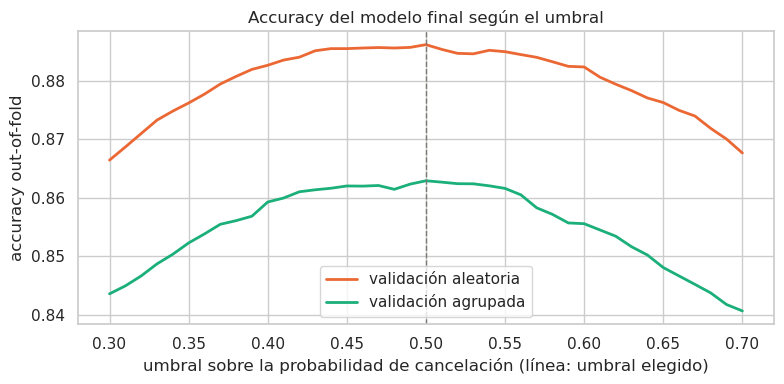

Umbral con mayor accuracy: 0.50 (accuracy 0.8862; con la validación agrupada, el mejor es 0.50).
Mejor umbral de cada fold: [0.45, 0.46, 0.47, 0.55, 0.43].
Umbrales a menos de 0,001 de la mejor accuracy: de 0.44 a 0.54.


In [45]:
THRESHOLD_GRID = np.round(np.arange(0.30, 0.701, 0.01), 2)
threshold_accuracy = pd.DataFrame(
    {scheme: [((final_proba[scheme] >= t) == Y_DEV).mean() for t in THRESHOLD_GRID] for scheme in CV_SCHEMES},
    index=THRESHOLD_GRID)
best_threshold = float(threshold_accuracy['aleatoria'].idxmax())
best_by_fold = []
for k in range(N_FOLDS):
    in_fold = FOLD_IDS['aleatoria'] == k
    fold_accuracy = [((final_proba['aleatoria'][in_fold] >= t) == Y_DEV[in_fold]).mean() for t in THRESHOLD_GRID]
    best_by_fold.append(float(THRESHOLD_GRID[int(np.argmax(fold_accuracy))]))
near_best = threshold_accuracy.index[threshold_accuracy['aleatoria'] >= threshold_accuracy['aleatoria'].max() - 0.001]

fig, ax = plt.subplots(figsize=(8, 4))
for scheme, color in [('aleatoria', '#eb6834'), ('agrupada', '#1baf7a')]:
    ax.plot(THRESHOLD_GRID, threshold_accuracy[scheme], color=color, linewidth=2, label=f'validación {scheme}')
ax.axvline(best_threshold, color=REFERENCE, linestyle='--', linewidth=1)
ax.set_xlabel('umbral sobre la probabilidad de cancelación (línea: umbral elegido)')
ax.set_ylabel('accuracy out-of-fold')
ax.set_title('Accuracy del modelo final según el umbral')
ax.legend(loc='lower center')
plt.tight_layout()
plt.show()

assert best_threshold == predictor.THRESHOLD == THRESHOLD
print(f"Umbral con mayor accuracy: {best_threshold:.2f} "
      f"(accuracy {threshold_accuracy.loc[best_threshold, 'aleatoria']:.4f}; "
      f"con la validación agrupada, el mejor es {threshold_accuracy['agrupada'].idxmax():.2f}).")
print(f'Mejor umbral de cada fold: {best_by_fold}.')
print(f'Umbrales a menos de 0,001 de la mejor accuracy: de {near_best.min():.2f} a {near_best.max():.2f}.')

- **El mejor umbral es 0,5 en los dos esquemas de validación.**
- **La curva es plana cerca del máximo:** entre 0,44 y 0,54, la accuracy queda a menos de 0,001 del máximo. El mejor umbral de cada fold va de 0,43 a 0,55, así que la diferencia entre esos valores es ruido.
- **Se usa 0,5:** es el máximo y el umbral natural de una probabilidad. Coincide con el baseline (sección 7.4).
- **Si la plataforma fijara costos distintos para cada error, el umbral se movería sin reentrenar** (sección 7.4). Para la competencia se mantiene el supuesto de costos iguales.

### 12.3 Qué cambios mejoraron el sistema y dónde

Se comparan por cohorte, con las predicciones *out-of-fold* de desarrollo, los tres modelos de 11.6:

- el baseline;
- el paso de hiperparámetros (Random Forest con `max_features = 0,2`);
- el modelo final, que suma la combinación con gradient boosting.

Se muestran las cohortes de la consigna, el tipo de reserva (única o en lote) y la región elegida en la sección 9. Sólo entran las cohortes de al menos 1.000 filas, porque en las más chicas una diferencia de AUC de milésimas es ruido.

In [46]:
MIN_ROWS_IMPROVEMENT = 1000
steps = {'baseline': baseline_eval, 'max_features': forest_for_ensemble, 'final': final_eval}
cohort_values = {
    'todas': pd.Series('todas las filas', index=analysis.index),
    'client_type': analysis['client_type'],
    'service_tier': analysis['service_tier'],
    'reserved_gpu_type': analysis['reserved_gpu_type'],
    'tipo de reserva': analysis['en_lote'],
    'región de la sección 9': pd.Series(np.where(REGION, 'región elegida', 'resto'), index=analysis.index),
}


def step_metrics(mask):
    row = {'filas': mask.sum()}
    for name, result in steps.items():
        proba = result['aleatoria']['proba'][mask]
        row[f'error_{name}'] = ((proba >= THRESHOLD) != Y_DEV[mask]).mean()
        row[f'auc_{name}'] = roc_auc_score(Y_DEV[mask], proba)
        row[f'auc_agrupada_{name}'] = roc_auc_score(Y_DEV[mask], result['agrupada']['proba'][mask])
    return row


rows = {}
for variable, values in cohort_values.items():
    for cohort in values.value_counts().index:
        mask = values.eq(cohort).to_numpy()
        if mask.sum() >= MIN_ROWS_IMPROVEMENT:
            rows[(variable, cohort)] = step_metrics(mask)
by_step = pd.DataFrame.from_dict(rows, orient='index').rename_axis(['variable', 'cohorte'])
improvement = pd.DataFrame({
    'filas': by_step['filas'],
    'error_baseline': by_step['error_baseline'],
    'error_final': by_step['error_final'],
    'delta_error': by_step['error_final'] - by_step['error_baseline'],
    'auc_baseline': by_step['auc_baseline'],
    'auc_final': by_step['auc_final'],
    'delta_auc_max_features': by_step['auc_max_features'] - by_step['auc_baseline'],
    'delta_auc_combinacion': by_step['auc_final'] - by_step['auc_max_features'],
    'delta_auc_agrupada': by_step['auc_agrupada_final'] - by_step['auc_agrupada_baseline'],
})
display(improvement.style.format({
    'filas': '{:.0f}', 'error_baseline': '{:.1%}', 'error_final': '{:.1%}', 'delta_error': '{:+.2%}',
    'auc_baseline': '{:.4f}', 'auc_final': '{:.4f}', 'delta_auc_max_features': '{:+.4f}',
    'delta_auc_combinacion': '{:+.4f}', 'delta_auc_agrupada': '{:+.4f}'}))

baseline_wrong = (baseline_eval['aleatoria']['proba'] >= THRESHOLD) != Y_DEV
final_wrong = (final_proba['aleatoria'] >= THRESHOLD) != Y_DEV
for name, mask in [('todas las filas', np.ones(len(Y_DEV), dtype=bool)), ('región elegida', REGION),
                   ('reservas en lote', analysis['en_lote'].eq('en lote').to_numpy())]:
    print(f'{name}: el modelo final corrige {(baseline_wrong & ~final_wrong & mask).sum()} errores del baseline '
          f'y comete {(~baseline_wrong & final_wrong & mask).sum()} nuevos.')

todas las filas: el modelo final corrige 597 errores del baseline y comete 530 nuevos.
región elegida: el modelo final corrige 481 errores del baseline y comete 413 nuevos.
reservas en lote: el modelo final corrige 19 errores del baseline y comete 46 nuevos.


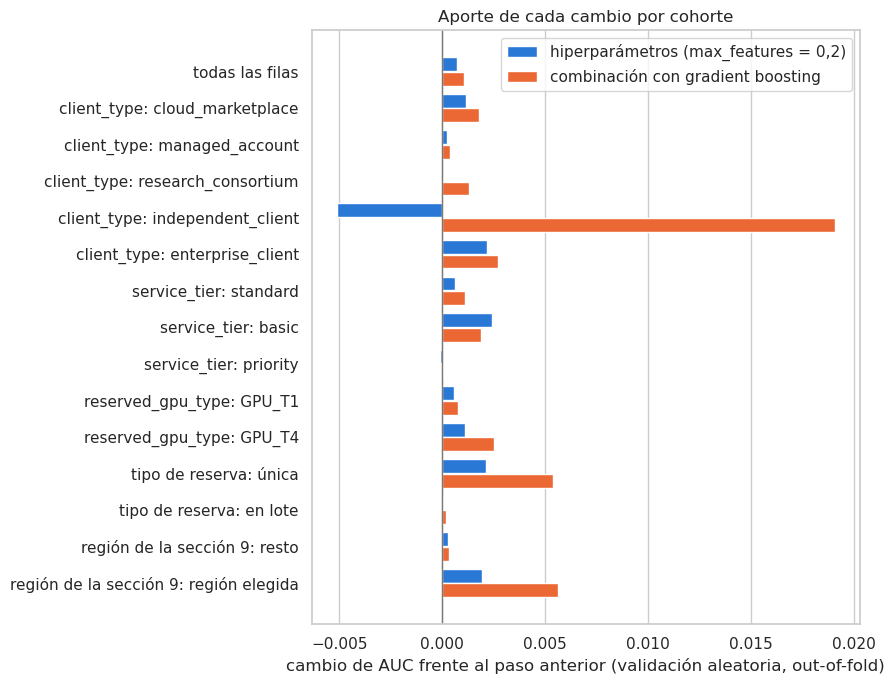

In [47]:
chart = improvement.iloc[::-1]
labels = [cohort if variable == 'todas' else f'{variable}: {cohort}' for variable, cohort in chart.index]
positions = np.arange(len(chart))
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(positions + 0.2, chart['delta_auc_max_features'], height=0.38, color=BLUE,
        label='hiperparámetros (max_features = 0,2)')
ax.barh(positions - 0.2, chart['delta_auc_combinacion'], height=0.38, color='#eb6834',
        label='combinación con gradient boosting')
ax.axvline(0, color=REFERENCE, linewidth=1)
ax.set_yticks(positions, labels)
ax.set_xlabel('cambio de AUC frente al paso anterior (validación aleatoria, out-of-fold)')
ax.set_title('Aporte de cada cambio por cohorte')
ax.grid(axis='y', visible=False)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

**¿Qué cambio aportó más?** La combinación con gradient boosting: +0,0011 de AUC en todas las filas, contra +0,0007 del ajuste de `max_features`. Con validación agrupada, la mejora total es más grande (+0,0042).

**¿La mejora fue global o de algunos subgrupos?** Fue específica: se concentra en las cohortes difíciles, que son las que el diagnóstico de la sección 7 marcó.

- **Reservas únicas y región elegida:** la AUC sube 0,0075 y el error baja 0,4 puntos. Son las cohortes con más margen.
- **`independent_client`:** es el caso más marcado. El ajuste de `max_features` empeoró su AUC (−0,005), pero la combinación la sube 0,019. **Inferencia:** gradient boosting aporta justo donde Random Forest ordena peor.
- **`basic` y `GPU_T4`:** la AUC sube unas 0,004. Siguen a `cloud_marketplace`, como en la sección 7.1.
- **En las cohortes fáciles casi no hay cambio:** en `managed_account`, `research_consortium`, `priority` y el resto fuera de la región, la AUC ya superaba 0,98 y cambia menos de 0,0015.
- **Las reservas en lote empeoran un poco con validación aleatoria:** el error pasa de 1,9 % a 2,1 % (19 errores corregidos y 46 nuevos). Es el costo de memorizar menos los lotes: con validación agrupada, también mejoran (+0,0020).

**En errores, el cambio neto es chico:** el modelo final corrige 597 errores del baseline y comete 530 nuevos. Reordena muchas reservas cercanas al umbral, por eso mejora más la AUC que la accuracy.

### 12.4 Evaluación única en test

El modelo final se entrena con todo desarrollo y se evalúa una sola vez en test. El baseline se evalúa también, sólo como referencia: test no se usa para elegir nada.

Para cada métrica se muestra un intervalo *bootstrap* del 95 %: se remuestrean las filas de test con reposición y se recalcula la métrica. Es una forma estándar de medir la incertidumbre de una métrica calculada sobre una sola muestra de test.

In [48]:
@memory.cache
def fit_predict_proba(model, X_train, y_train, X_eval):
    return clone(model).fit(X_train, y_train).predict_proba(X_eval)[:, 1]


X_test_prep = prepare_features(X_test)
Y_TEST = y_test.to_numpy()
test_proba = {
    'baseline': fit_predict_proba(baseline, X_dev_prep, y_dev, X_test_prep),
    'final': fit_predict_proba(predictor.build_model(), X_dev_prep, y_dev, X_test_prep),
}


def decision_metrics(y_true, proba):
    predicted = proba >= THRESHOLD
    return {'auc': roc_auc_score(y_true, proba), 'accuracy': (predicted == y_true).mean(),
            'tasa_fp': predicted[y_true == 0].mean(), 'tasa_fn': 1 - predicted[y_true == 1].mean()}


test_summary = pd.DataFrame({
    'baseline, test': decision_metrics(Y_TEST, test_proba['baseline']),
    'final, test': decision_metrics(Y_TEST, test_proba['final']),
    'final, out-of-fold con validación aleatoria': decision_metrics(Y_DEV, final_proba['aleatoria']),
    'final, out-of-fold con validación agrupada': decision_metrics(Y_DEV, final_proba['agrupada']),
}).T
METRIC_FORMAT = {'auc': '{:.4f}', 'accuracy': '{:.4f}', 'tasa_fp': '{:.1%}', 'tasa_fn': '{:.1%}'}
display(test_summary.style.format(METRIC_FORMAT))
display(pd.DataFrame(confusion_matrix(Y_TEST, test_proba['final'] >= THRESHOLD),
                     index=['real: se ejecuta', 'real: se cancela'],
                     columns=['predicho: se ejecuta', 'predicho: se cancela']))

BOOTSTRAP_ROUNDS = 2000
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_rows = []
for _ in range(BOOTSTRAP_ROUNDS):
    sample = rng.integers(0, len(Y_TEST), len(Y_TEST))
    final_sample = decision_metrics(Y_TEST[sample], test_proba['final'][sample])
    baseline_sample = decision_metrics(Y_TEST[sample], test_proba['baseline'][sample])
    bootstrap_rows.append({
        'auc del modelo final': final_sample['auc'],
        'accuracy del modelo final': final_sample['accuracy'],
        'diferencia de auc con el baseline': final_sample['auc'] - baseline_sample['auc'],
        'diferencia de accuracy con el baseline': final_sample['accuracy'] - baseline_sample['accuracy'],
    })
bootstrap = pd.DataFrame(bootstrap_rows)
intervals = bootstrap.quantile([0.025, 0.975]).T.set_axis(['límite inferior', 'límite superior'], axis=1)
intervals['proporción de remuestreos con diferencia positiva'] = [
    np.nan, np.nan, (bootstrap.iloc[:, 2] > 0).mean(), (bootstrap.iloc[:, 3] > 0).mean()]
display(intervals.style.format({'límite inferior': '{:.4f}', 'límite superior': '{:.4f}',
                                'proporción de remuestreos con diferencia positiva': '{:.1%}'}, na_rep='—'))

,auc,accuracy,tasa_fp,tasa_fn
"baseline, test",0.9588,0.8888,6.4%,17.7%
"final, test",0.9601,0.8891,7.2%,16.5%
"final, out-of-fold con validación aleatoria",0.9575,0.8862,7.7%,16.5%
"final, out-of-fold con validación agrupada",0.9417,0.8629,8.8%,20.6%


,predicho: se ejecuta,predicho: se cancela
real: se ejecuta,5174,404
real: se cancela,657,3334


,límite inferior,límite superior,proporción de remuestreos con diferencia positiva
auc del modelo final,0.9566,0.9634,—
accuracy del modelo final,0.8823,0.8951,—
diferencia de auc con el baseline,0.0003,0.0023,99.4%
diferencia de accuracy con el baseline,-0.0031,0.0036,54.4%


- **Resultado en test:** AUC 0,960 (intervalo del 95 %: 0,957 a 0,963) y accuracy 0,889 (0,882 a 0,895).
- **Queda algo por encima de la validación cruzada** (0,9575 y 0,886), dentro del intervalo. **Inferencia:** el modelo se entrenó con todo desarrollo (38.273 filas, contra unas 30.600 en cada fold), y la curva aleatoria de la sección 8 todavía sube con más filas.
- **El tipo de error es el mismo que en desarrollo:** el modelo no anticipa el 16,5 % de las cancelaciones (657) y marca como cancelación el 7,2 % de las que se ejecutan (404).
- **Frente al baseline:**
  - la mejora de AUC se confirma (+0,0013, intervalo de 0,0003 a 0,0023, positiva en el 99 % de los remuestreos);
  - la de accuracy no se distingue de cero (+0,0003, intervalo de −0,003 a +0,004). Coincide con desarrollo: el modelo final ordena mejor, pero cambia poco la decisión con umbral 0,5.
- **Inferencia:** los intervalos remuestrean filas y no tienen en cuenta que las filas de un mismo lote están correlacionadas, así que probablemente subestiman algo la incertidumbre.

Las mismas métricas por subgrupo de test, junto al error *out-of-fold* del modelo final en la misma cohorte de desarrollo:

- **Gemela en desarrollo:** si la fila de test tiene una fila idéntica en desarrollo (38,6 % de test, sección 2).
- **Región elegida:** reservas de `cloud_marketplace` sin ninguna otra fila idéntica en el archivo. Es la definición de la sección 9, aplicada a test.
- **Cohortes de la consigna,** con al menos 100 filas en test.

In [49]:
all_keys = duplicate_key(df)
single_in_file = all_keys.map(all_keys.value_counts()).eq(1).loc[X_test.index].to_numpy()
test_groups = {
    'gemela en desarrollo': (pd.Series(np.where(test_has_twin_in_dev, 'con gemela', 'sin gemela')), None),
    'región de la sección 9': (
        pd.Series(np.where(X_test['client_type'].eq('cloud_marketplace').to_numpy() & single_in_file,
                           'región elegida', 'resto')),
        pd.Series(np.where(REGION, 'región elegida', 'resto'))),
}
for column in ['client_type', 'service_tier', 'reserved_gpu_type']:
    test_groups[column] = (X_test[column].reset_index(drop=True), analysis[column].reset_index(drop=True))


def test_cohort_metrics(test_values, dev_values, min_rows=100):
    rows = {}
    for cohort in test_values.value_counts().index:
        mask = test_values.eq(cohort).to_numpy()
        if mask.sum() < min_rows:
            continue
        predicted = test_proba['final'][mask] >= THRESHOLD
        row = {'filas_test': mask.sum(), 'tasa_cancelacion': Y_TEST[mask].mean(),
               'error_test': (predicted != Y_TEST[mask]).mean(),
               'auc_test': (roc_auc_score(Y_TEST[mask], test_proba['final'][mask])
                            if len(np.unique(Y_TEST[mask])) == 2 else np.nan),
               'error_out_of_fold': np.nan}
        if dev_values is not None:
            dev_mask = dev_values.eq(cohort).to_numpy()
            row['error_out_of_fold'] = ((final_proba['aleatoria'][dev_mask] >= THRESHOLD) != Y_DEV[dev_mask]).mean()
        rows[cohort] = row
    return pd.DataFrame.from_dict(rows, orient='index')


test_cohorts = pd.concat({name: test_cohort_metrics(*values) for name, values in test_groups.items()},
                         names=['variable', 'cohorte'])
display(test_cohorts.style.format({'filas_test': '{:.0f}', 'tasa_cancelacion': '{:.1%}', 'error_test': '{:.1%}',
                                   'auc_test': '{:.3f}', 'error_out_of_fold': '{:.1%}'}, na_rep='—'))

- **El diagnóstico por cohortes se sostiene en datos no vistos.**
  - En las cohortes con más de 300 filas de test, el error queda a menos de 2 puntos del *out-of-fold* (la mayor diferencia es la de `basic`: 17,0 % contra 18,5 %), y en la mayoría a menos de 1 punto.
  - Las diferencias más grandes son las de las GPU poco frecuentes: `GPU_T6` (2,5 puntos, 233 filas) y `GPU_T2` (4,5 puntos, 126 filas). Con tan pocas filas, el error de test tiene un desvío de unos 3 puntos, así que esas diferencias son esperables.
- **Región elegida:** 20,7 % de error en test, contra 21,0 % en desarrollo. Sigue siendo el problema principal: tiene el 40 % de las filas de test y el 75 % de sus errores.
- **Con gemela en desarrollo, el modelo casi no se equivoca** (0,9 % de error, AUC 0,999).
- **Sin gemela, el error es de 17,5 % y la AUC de 0,889.** Es casi lo mismo que en las reservas únicas de desarrollo (17,3 % y 0,889, en 12.3). Ese es el rendimiento real del modelo con reservas que no vio.

### 12.5 Rendimiento esperado en datos nuevos

Depende de cómo sean los datos nuevos, que no conocemos (sección 2). Hay dos escenarios:

| Escenario | Mejor estimación | AUC | Accuracy |
|---|---|---:|---:|
| Mismo conjunto de reservas, con gemelas en la proporción del CSV (supuesto para el Model Score) | test | 0,960 (0,957 a 0,963) | 0,889 (0,882 a 0,895) |
| Reservas nuevas, sin gemelas en el entrenamiento | validación agrupada | 0,942 | 0,863 |

- **Primer escenario:** el predictor enviado se entrena con todo el CSV, así que tiene más gemelas para reconocer que el modelo evaluado en test. Si cambia algo, debería rendir un poco mejor.
- **Segundo escenario:** si las reservas nuevas fueran casi todas individuales, la accuracy se acercaría a la de las filas de test sin gemela (0,825). La validación agrupada da 0,863 porque incluye lotes nunca vistos, que siguen siendo fáciles.
- **Regla práctica (inferencia):** en test, la accuracy es aproximadamente 0,99 × (proporción de filas con gemela) + 0,825 × (resto). Cuantas menos gemelas tenga el conjunto de evaluación, más se acerca a 0,83.
- **Riesgo sin medir:** si los datos nuevos son de fechas posteriores, `execution_year` toma valores que el modelo no vio y puede haber deriva (sección 3.6). Ninguna de las dos estimaciones lo cubre.

### 12.6 Predictor entregado

Como se propuso en la sección 8, el predictor se reentrena con desarrollo y test juntos (47.842 filas), con la misma receta y el mismo umbral. Lo que se evaluó en 12.4 es la receta; el modelo enviado ve un 25 % más de filas, así que, si cambia algo, debería rendir un poco mejor que lo estimado.

El paquete `predictor_v1_Grupo_11.zip` lleva:

- `predictor_v1_Grupo_11.py`, con las funciones `predictor_v1_Grupo_11(X)` y `predictor_v1_Grupo_11_proba(X)`;
- `predictor_v1_Grupo_11.joblib`, el modelo entrenado;
- `requirements.txt`, con las versiones exactas con que se entrenó;
- `README.md`, con las instrucciones de uso.

La prueba descomprime el paquete en una carpeta temporal y lo usa desde un proceso de Python nuevo, con filas crudas del CSV y en los formatos de entrada que acepta el predictor.

In [50]:
import subprocess
import sys
import zipfile

final_model = predictor.train(df.drop(columns=TARGET), df[TARGET])
joblib.dump(final_model, predictor.MODEL_PATH, compress=3)
print(f'Modelo entrenado con {len(df)} filas; gradient boosting usó '
      f"{final_model.named_estimators_['gradient_boosting'][-1].n_iter_} árboles. "
      f'{predictor.MODEL_PATH.name}: {predictor.MODEL_PATH.stat().st_size / 1e6:.1f} MB.')

PACKAGE = Path('predictor_v1_Grupo_11.zip')
PACKAGE_CONTENTS = {
    'predictor_v1_Grupo_11.py': Path('predictor_v1_Grupo_11.py'),
    'predictor_v1_Grupo_11.joblib': predictor.MODEL_PATH,
    'requirements.txt': Path('requirements_predictor.txt'),
    'README.md': Path('README_predictor.md'),
}
with zipfile.ZipFile(PACKAGE, 'w', zipfile.ZIP_DEFLATED) as package:
    for name, source in PACKAGE_CONTENTS.items():
        package.write(source, name)
print(f'{PACKAGE.name}: {PACKAGE.stat().st_size / 1e6:.1f} MB, con {list(PACKAGE_CONTENTS)}.')

Modelo entrenado con 47842 filas; gradient boosting usó 460 árboles. predictor_v1_Grupo_11.joblib: 18.1 MB.


predictor_v1_Grupo_11.zip: 17.8 MB, con ['predictor_v1_Grupo_11.py', 'predictor_v1_Grupo_11.joblib', 'requirements.txt', 'README.md'].


In [51]:
SMOKE_TEST = '''
from pathlib import Path

import numpy as np
import pandas as pd

import predictor_v1_Grupo_11 as predictor
from predictor_v1_Grupo_11 import predictor_v1_Grupo_11, predictor_v1_Grupo_11_proba

assert Path(predictor.__file__).resolve().parent == Path.cwd().resolve()
data = pd.read_csv('muestra.csv')
features = data.drop(columns='canceled_job')
predicted = predictor_v1_Grupo_11(data)
assert len(predicted) == len(data) and set(np.unique(predicted)) <= {0, 1}
assert (predictor_v1_Grupo_11(features) == predicted).all()
assert (predictor_v1_Grupo_11(features.to_numpy()) == predicted).all()
assert (predictor_v1_Grupo_11(data.to_numpy()) == predicted).all()
assert predictor_v1_Grupo_11(features.iloc[0].to_numpy()).tolist() == [predicted[0]]
assert predictor_v1_Grupo_11(features.iloc[0]).tolist() == [predicted[0]]
np.save('proba.npy', predictor_v1_Grupo_11_proba(features))
'''

sample = df.sample(1000, random_state=RANDOM_STATE)
with tempfile.TemporaryDirectory() as folder:
    folder = Path(folder)
    with zipfile.ZipFile(PACKAGE) as package:
        package.extractall(folder)
    sample.to_csv(folder / 'muestra.csv', index=False)
    (folder / 'prueba.py').write_text(SMOKE_TEST)
    run = subprocess.run([sys.executable, 'prueba.py'], cwd=folder, capture_output=True, text=True)
    assert run.returncode == 0, run.stderr
    command_line = subprocess.run([sys.executable, 'predictor_v1_Grupo_11.py', 'predecir', 'muestra.csv',
                                   'salida.csv'], cwd=folder, capture_output=True, text=True)
    assert command_line.returncode == 0, command_line.stderr
    outside_proba = np.load(folder / 'proba.npy')
    command_line_predictions = pd.read_csv(folder / 'salida.csv')[TARGET].to_numpy()

inside_proba = final_model.predict_proba(prepare_features(sample))[:, 1]
assert np.allclose(outside_proba, inside_proba)
assert (command_line_predictions == (inside_proba >= predictor.THRESHOLD)).all()
print(f'Proceso nuevo: {len(sample)} filas crudas del CSV, mismas probabilidades que en el notebook '
      f'(diferencia máxima {np.abs(outside_proba - inside_proba).max():.1e}).')
print('Formatos probados: DataFrame con y sin canceled_job, array de 33 y de 34 columnas, '
      'una fila como array y como Series, y la línea de comandos.')

Proceso nuevo: 1000 filas crudas del CSV, mismas probabilidades que en el notebook (diferencia máxima 1.1e-16).
Formatos probados: DataFrame con y sin canceled_job, array de 33 y de 34 columnas, una fila como array y como Series, y la línea de comandos.


- **El modelo entrenado con todo el CSV pesa 18,1 MB y el paquete 17,8 MB.** Entra en el límite habitual de adjuntos (unos 25 MB). Si el mail con la presentación y el notebook lo supera, el predictor puede ir en un mail aparte.
- **El paquete funciona fuera del notebook.** En un proceso nuevo, desde la carpeta descomprimida, da las mismas probabilidades que el modelo en memoria, con los formatos de entrada probados y por línea de comandos.
- **La prueba usa filas con que se entrenó el modelo:** verifica que el paquete reproduce el modelo, no su rendimiento. El rendimiento es el de 12.4 y 12.5.
- **Si en la cátedra el `.joblib` no carga** por una versión distinta de scikit-learn, el README del paquete explica cómo regenerarlo con la misma receta (`python predictor_v1_Grupo_11.py entrenar ...`).